# PETadex.v260701 Creation: 4. Creating the PETadex HMMs

> **Author:** Thomas Quigley\
> **Date Started:** July 22nd, 2026\
> **Date Finished:** September 13th, 2026\
> **Input:** \
> s3://petadex/petadex.v260701/3_msa_cleaning/plasticome.v2.sequence_annotations.csv\
> s3://petadex/petadex.v260701/3_msa_cleaning/plasticome_msas/plasticome.component_\*.afa\
> s3://petadex/petadex.v260701/2_nr_search/petadex-nr.v260701.significant-hits.fastaa\
> s3://petadex-protein-structures/af_db_v260701/structures\
> s3://petadex-protein-structures/af_db_v260701/mappings/record_structure_map.tsv\
> **Output:** \
> s3://petadex/petadex.v260701/4_hmm_creation/petadex_hmms/petadex.v260701-\*.hmm
---

## 1. Objective

The goal of this notebook is to create the PETadex-HMMs that will be used to quality control the PETadex sequences, annotating their catalytic residues and fragment-ness (complete HMM hit or not). The HMMs will be seeded with the Plasticome sequences and will be iteratively created using a script that is similar to JACK HMMER but ensures that sequences entering the HMM must have the correct canonical catalytic residues.

I realized that last time I made these HMMs, I had no way of figuring out if the HMMs were overfitting. I will create a training set by selecting all hits below E-10 from the nr search, and will have the validation/search set as all hits below E-5. By restricting the sequences that can be added to the HMMs to only lower e-value hits, it forces the HMMs to better represent the input query sequences, vs. representing the entire search set.

I will test out the quality of the HMMs for each iteration by visually looking at the E-value distribution of each HMM and seeing the number of "complete" HMM hits (conserved on all catalytic residues). If the HMMs are overfitting, then we should see a bimodal distribution of high e-value and low e-value hits (similar to HMM seed and not), and if the HMMs are poor, we will see that most of the hits are not "complete" HMM hits. Therefore I will try to optimize the settings of the script to minimize this bimodal distribution / maximize the average e-value per hit and retrieve as many "complete" hits from the validation set as possible.

Additionally, I will get as many structures as possible for each sub-component (max = 10k), and divide the structures into distinct domains. Then I will see if the HMM hits creep into the other domains, or what portion of the main catalytic domain they hit to. This will be another metric I will use to judge the quality of the HMM, to ensure that the HMMs only hit to the catalytic domain and that the --symfrac is not to stringent and reduces the size of the HMM too much.

### 1.1. Place in the Project
---
We want to ensure all the sequences in the PETadex contain the catalytic domain, and describe how fragmented they are. These HMMs will be used for the following purposes:
1. To extract only the catalytic domain for the Logan search (so we don't waste money searching accessory domains).
2. To annotate the catalytic domains for each sequence on the website.
3. To annotate the catalytic residues for each sequence on the website.
4. To annotate secondary residues (important non-catalytic) for each sequence on the website.
5. The Logan assembly is inherently fragmented, and so the HMMs can tell us which sequences are non-fragmented (full HMM hit).
6. Discover motifs within the HMM logos, which may inform mechanistic analyses.

## 2. Methods
### 2.0. Install requirements
---
- HMMER 3.4 (Aug 2023); http://hmmer.org/
- AFRAGMENTER 0.0.6
- HHalign 3.3.0
- HHmake 3.3.0
- Easel 0.49 (esl-reformat)
- networkx 3.6.1

### 2.1. Downloading structures to validate the HMM envelope hit range
---
It's hard to tell just how good these HMMs actually are without looking at how and where they hit to a protein. A way that we can make this validation automatic is by taking as many structures of the NCBI nr hits as possible and finding out where the domain start and stop sites are. Then we can see the portion of the catalytic domain that the HMMs hit to.

Alex has gotten as many folds from AF DB as possible and has a mapping csv so I can easily extract the structures.


In [ ]:
%%bash
set -uo pipefail

# ───────────────────────────────────────── #
# DOWNLOAD MAX 1K STRUCTURES PER COMPONENT #
# ───────────────────────────────────────── #

# ─── INPUT  ─── #
S3_MAPPING_TSV="s3://petadex-protein-structures/af_db_v260701/mappings/record_structure_map.tsv"
# rec_id    query_petadex_id    component_id    matched_accession    uniprot_ac    s3_key
# 7    PL138    C028    AVI23960    A0A2P1AFT5    s3://petadex-protein-structures/af_db_v260701/structures/AF-A0A2P1AFT5-F1-model_v4.cif

# ─── OUTPUT  ─── #
S3_MAPPING_TSV_LOCAL="./4_hmm_creation/working/structure_analysis/record_structure_map.tsv"
DOWNLOADED_STRUCTURES_LIST="./4_hmm_creation/working/structure_analysis/structure_accession_mappings.csv"
# component_id,matched_accession,af_db_accession
# C001,AVI23960,AF-A0A2P1AFT5-F1-model_v6

# ─── PARAMETERS  ─── #
MAX_PER_COMPONENT=1000
SEED=260823
MAX_JOBS=16 # concurrent downloads against the AlphaFold file server

mkdir -p -- "$(dirname -- "${S3_MAPPING_TSV_LOCAL}")"

# ─── RETRIEVE THE LIST OF AF DB ACCESSIONS ─── #
aws s3 cp "${S3_MAPPING_TSV}" "${S3_MAPPING_TSV_LOCAL}"

python3 - "${S3_MAPPING_TSV_LOCAL}" "${DOWNLOADED_STRUCTURES_LIST}" "${MAX_PER_COMPONENT}" "${SEED}" <<'PYEOF'
import csv
import random
import re
import sys
from collections import defaultdict

mapping_path, output_path, max_per_component, seed = sys.argv[1], sys.argv[2], int(sys.argv[3]), int(sys.argv[4])
component_pattern = re.compile(r"^C\d{3}$")

# component_id -> {uniprot_ac: matched_accession} (dict dedupes to one row per unique structure,
# since the same AF-DB structure can be hit by more than one NCBI accession within a component)
by_component = defaultdict(dict)
n_total = 0
n_bugged = 0

with open(mapping_path, newline="") as f:
    reader = csv.DictReader(f, delimiter="\t")
    for row in reader:
        n_total += 1
        component_id = row["component_id"]
        if not component_pattern.match(component_id):
            n_bugged += 1  # corrupted row (e.g. a stray bitscore/e-value in this column) — skip
            continue
        by_component[component_id].setdefault(row["uniprot_ac"], row["matched_accession"])

rng = random.Random(seed)
with open(output_path, "w", newline="") as f:
    writer = csv.writer(f, lineterminator="\n")
    writer.writerow(["component_id", "matched_accession", "af_db_accession"])
    print(f"{'component':<10}{'available':>12}{'sampled':>10}")
    for component_id in sorted(by_component):
        structures = list(by_component[component_id].items())  # (uniprot_ac, matched_accession)
        rng.shuffle(structures)
        sampled = structures[:max_per_component]
        print(f"{component_id:<10}{len(structures):>12}{len(sampled):>10}")
        for uniprot_ac, matched_accession in sampled:
            af_db_accession = f"AF-{uniprot_ac}-F1"
            writer.writerow([component_id, matched_accession, af_db_accession])

print(f"\n{n_total:,} total rows read, {n_bugged:,} skipped for a malformed component_id (not matching C### format)")
PYEOF

echo "Wrote accession list to ${DOWNLOADED_STRUCTURES_LIST}"

download: s3://petadex-protein-structures/af_db_v260701/mappings/record_structure_map.tsv to 4_hmm_c   MiB/s) with 1 file(s) remaining    MiB/s) with 1 file(s) remaining    MiB/s) with 1 file(s) remaining   6 MiB/s) with 1 file(s) remaining  2 MiB/s) with 1 file(s) remaining  7 MiB/s) with 1 file(s) remaining  g  0 MiB/s) with 1 file(s) remaining  6 MiB/s) with 1 file(s) remaining  3 MiB/s) with 1 file(s) remaining  g  3 MiB/s) with 1 file(s) remaining  g  2 MiB/s) with 1 file(s) remaining  3 MiB/s) with 1 file(s) remaining  0 MiB/s) with 1 file(s) remaining  g  5 MiB/s) with 1 file(s) remaining  g  0 MiB/s) with 1 file(s) remaining  5 MiB/s) with 1 file(s) remaining  7 MiB/s) with 1 file(s) remaining  8 MiB/s) with 1 file(s) remaining  3 MiB/s) with 1 file(s) remaining  6 MiB/s) with 1 file(s) remaining  9 MiB/s) with 1 file(s) remaining  4 MiB/s) with 1 file(s) remaining  7 MiB/s) with 1 file(s) remaining  1 MiB/s) with 1 file(s) remaining  1 MiB/s) with 1 file(s) remaining  3 MiB/s)

### 2.1.1. Cut the structures using AFRAGMENTER
---
AFRAGMENTER partions structures into their domains. This codeblock multithreads AFRAGMENTER to cut all of the test structures and output them into the following table:
| component_id | matched_accession | aa_positions_of_cutsites |
| - | - | - |
| C028 | AVI23960 | 50,300,500 |

This will create an easy table to look up accessions for later validation steps.

In [ ]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #

import csv
import sys
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

from afragmenter import AFragmenter, fetch_afdb_data

# ─── INPUT ─── #
DOWNLOADED_STRUCTURES_LIST = "./4_hmm_creation/working/structure_analysis/structure_accession_mappings.csv"
# component_id,matched_accession,af_db_accession
# C001,AVI23960,AF-A0A2P1AFT5-F1

# ─── OUTPUT ─── #
CUTSITES_CSV = "./4_hmm_creation/working/structure_analysis/test-set_cutsites.csv"
# component_id,match_accession,aa_positions_of_cutsites

# ─── PARAMETERS ─── #
MAX_WORKERS = 32  # concurrent AFDB fetches + AFRAGMENTER clustering jobs; network-bound, so pushed higher than a CPU-bound job would warrant

# ─────────────── #
# RUN AFRAGMENTER #
# ─────────────── #

# ─── GET A LIST OF AF_DB ACCESSIONS ─── #
with open(DOWNLOADED_STRUCTURES_LIST, newline="") as f:
    test_structures = list(csv.DictReader(f))

def cut_structure(row):
    af_db_accession = row["af_db_accession"]
    uniprot_ac = af_db_accession.split("-")[1]  # "AF-{uniprot_ac}-F1" -> uniprot_ac

    # ─── RUN AFRAGMENTER ─── #
    pae, structure = fetch_afdb_data(uniprot_ac)
    fragmented_pae = AFragmenter(pae, threshold=3)
    result = fragmented_pae.cluster()

    """
    Output table example
    ┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
    ┃ Domain ┃ Number of Residues ┃ Chopping ┃
    ┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
    │ 1      │                137 │   10-146 │
    │ 2      │                 47 │  147-193 │
    │ 3      │                 81 │  194-274 │
    └────────┴────────────────────┴──────────┘
    """

    # ─── EXTRACT CUT SITES AND ADD TO SUMMARY CSV ─── #
    all_segments = [segment for domain in result.cluster_intervals.values() for segment in domain] # get all cut sites from all clusters
    all_segments.sort(key=lambda segment: segment[0])
    cutsites = [end + 1 for _, end in all_segments]  # 1-indexed, matching AFRAGMENTER's own chopping convention

    return row["component_id"], row["matched_accession"], cutsites

# ─── REPEAT FOR EACH STRUCTURE, MULTITHREADED ─── #
n_ok = 0
failed = []
component_counts = Counter()  # component_id -> number of structures cut and parsed successfully
total = len(test_structures)

with open(CUTSITES_CSV, "w", newline="") as out_f:
    writer = csv.writer(out_f, lineterminator="\n")
    writer.writerow(["component_id", "matched_accession", "aa_positions_of_cutsites"])

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        futures = {pool.submit(cut_structure, row): row for row in test_structures}
        for future in as_completed(futures):
            row = futures[future]
            try:
                component_id, matched_accession, cutsites = future.result()
            except Exception as e:
                failed.append((row["af_db_accession"], str(e)))
            else:
                writer.writerow([component_id, matched_accession, ",".join(str(c) for c in cutsites)])
                component_counts[component_id] += 1
                n_ok += 1

            # ─── REAL-TIME PROGRESS, OVERWRITTEN IN PLACE AS STRUCTURES COMPLETE ─── #
            n_done = n_ok + len(failed)
            sys.stdout.write(f"\rParsed {n_done:,}/{total:,} structures ({n_ok:,} ok, {len(failed):,} failed)")
            sys.stdout.flush()

print()  # move past the in-place progress line before the summary below
print(f"Cut and parsed {n_ok:,}/{total:,} structures ({len(failed):,} failed) -> {CUTSITES_CSV}")
if failed:
    print("Failed accessions:")
    for af_db_accession, error in failed[:20]:
        print(f"  {af_db_accession}: {error}")

# ─── PER-COMPONENT BREAKDOWN OF HOW MANY STRUCTURES WERE CUT AND PARSED ─── #
print()
print(f"{'component':<10}{'cut & parsed':>15}")
for component_id in sorted(component_counts):
    print(f"{component_id:<10}{component_counts[component_id]:>15,}")

# ─── HEAD THE OUTPUT FILE TO VIEW ─── #
with open(CUTSITES_CSV) as f:
    for i, line in enumerate(f):
        if i >= 10:
            break
        print(line, end="")

Parsed 36,322/36,322 structures (36,321 ok, 1 failed)
Cut and parsed 36,321/36,322 structures (1 failed) -> ./4_hmm_creation/structure_analysis/test-set_cutsites.csv
Failed accessions:
  AF-A0A6J0NRI6-F1: 404 Client Error: Not Found for url: https://alphafold.ebi.ac.uk/api/prediction/A0A6J0NRI6

component    cut & parsed
C001                1,000
C002                1,000
C003                1,000
C004                1,000
C005                1,000
C006                1,000
C007                1,000
C008                  161
C009                  409
C010                   66
C011                  372
C012                1,000
C013                  487
C014                1,000
C015                1,000
C016                1,000
C017                1,000
C018                  893
C019                1,000
C020                1,000
C021                   70
C022                1,000
C023                   26
C024                1,000
C025                1,000
C026                1,000
C

### 2.1.2. Visualize the domain segregation
---
Using the built in PDB image creator of AFRAGMENTER, I want to see the cut sites for about 10 structures in each component. If the cut sites are in the middle of the domain, or out of the domain, it will influence the interpretability later on.

In [ ]:
# ──────────────────────────────── #
# VISUALIZE DOMAIN CUT SITES (3D) #
# ──────────────────────────────── #

import csv
import os
import random
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

try:
    import py3Dmol  # noqa: F401
except ImportError:
    %pip install -q py3Dmol

from afragmenter import AFragmenter, fetch_afdb_data

# ─── INPUT ─── #
DOWNLOADED_STRUCTURES_LIST = "./4_hmm_creation/working/structure_analysis/structure_accession_mappings.csv"
# component_id,matched_accession,af_db_accession

# ─── OUTPUT ─── #
IMAGE_DIR = "./4_hmm_creation/images/pdb_cutsites"
# {component_id}__{matched_accession}.html, one interactive structure per sampled accession, colored

# ─── PARAMETERS ─── #
N_PER_COMPONENT = 10
SEED = 260824
PAE_THRESHOLD = 3  # match the threshold used to cut the structures in 2.1.1, so the same cut sites are shown
MAX_WORKERS = 16

# ─── SAMPLE ~10 STRUCTURES PER COMPONENT ─── #
with open(DOWNLOADED_STRUCTURES_LIST, newline="") as f:
    by_component = defaultdict(list)
    for row in csv.DictReader(f):
        by_component[row["component_id"]].append(row)

rng = random.Random(SEED)
sampled_rows = []
for component_id in sorted(by_component):
    structures = by_component[component_id]
    rng.shuffle(structures)
    sampled_rows.extend(structures[:N_PER_COMPONENT])

# ─── RE-FETCH PAE/STRUCTURE AND RE-CLUSTER EACH SAMPLED STRUCTURE ─── #
def fragment_structure(row):
    uniprot_ac = row["af_db_accession"].split("-")[1]  # "AF-{uniprot_ac}-F1" -> uniprot_ac
    pae, structure = fetch_afdb_data(uniprot_ac)
    result = AFragmenter(pae, threshold=PAE_THRESHOLD).cluster()
    return row, structure, result

fragmented = []
failed = []
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    futures = {pool.submit(fragment_structure, row): row for row in sampled_rows}
    for future in as_completed(futures):
        row = futures[future]
        try:
            fragmented.append(future.result())
        except Exception as e:
            failed.append((row["af_db_accession"], str(e)))

fragmented.sort(key=lambda item: (item[0]["component_id"], item[0]["matched_accession"]))
print(f"Fragmented {len(fragmented):,}/{len(sampled_rows):,} sampled structures ({len(failed):,} failed)")
if failed:
    print("Failed accessions:")
    for af_db_accession, error in failed:
        print(f"  {af_db_accession}: {error}")

# ─── SAVE THE PDB IMAGE, COLORED BY DOMAIN, FOR EACH SAMPLED STRUCTURE ─── #
os.makedirs(IMAGE_DIR, exist_ok=True)
for row, structure, result in fragmented:
    print(f"\n{row['component_id']} | {row['matched_accession']} | {row['af_db_accession']}")
    result.print_result()
    image_path = os.path.join(IMAGE_DIR, f"{row['component_id']}__{row['matched_accession']}.html")
    result.py3Dmol(structure).write_html(image_path)

print(f"\nSaved {len(fragmented):,} interactive structures (colored by domain) -> {IMAGE_DIR}/")


Fragmented 460/460 sampled structures (0 failed)

C001 | ETI44273 | AF-V9F0J5-F1
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Domain ┃ Number of Residues ┃ Chopping ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ 1      │                313 │    7-319 │
└────────┴────────────────────┴──────────┘

C001 | SCL66196 | AF-A0A1C6VIL9-F1
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Domain ┃ Number of Residues ┃ Chopping ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ 1      │                 38 │     1-38 │
│ 2      │                258 │   39-296 │
└────────┴────────────────────┴──────────┘

C001 | SCY98663 | AF-A0A1G5KDG0-F1
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Domain ┃ Number of Residues ┃ Chopping ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━┩
│ 1      │                275 │    8-282 │
└────────┴────────────────────┴──────────┘

C001 | SHJ83340 | AF-A0A1M6MIZ8-F1
┏━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━┓
┃ Domain ┃ Number of Residues ┃ Chopping ┃
┡━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━

**NOTE:**\
The catlytic domains are often cut at lids or caps due to the flexibility of those regions. Therefore, later analysis scripts must take these lids and caps into consideration, or else the HMM hit range will be compared to just have of a domain.

![](../resources/260722_issue119_4_hmm_creation/example_of_lid_cutsite.png)

### 2.2. Subsetting the nr output for the training and validation sets
---
In this code block we are going to create the training and validation sets for building the HMMs. These sets are going to be the combination of the significant hits (below 1.0E-5) from the NCBI nr search and the search query sequences (PETadex-Plasticome.v260701 proteins). The PETadex-Plasticome.v260701 proteins will be added to the training set and not the validation set.
- Training = hits below e-10
- Validation = above e-10

These sets will then separated into fastaas per component, that way the time to run the HMMbuild pipeline is reduced substantialy.


In [ ]:
# ─────────────────────────────────── #
# CREATE TRAINING AND VALIDATION SETS #
# ─────────────────────────────────── #

import os
from collections import Counter

# ─── INPUT ─── #
NR_HITS = "../s3/2_nr_search/petadex-nr.v260701.significant-hits.fastaa"
"""
This file is already a subset of the hits from nr that are below the e-5 cutoff. Header is in the format of:

>genbank_accession:genbank_accession:ect|e_value|pid|bitscore|query_petadex_id|component_id

ex.
>WP_305403363.1|7.24e-11|23.5|73.6|PL181|C034
MNLHYQVEGDGKTIILIHGLFGSAANLGLLARSLKNKYKVISVDLRNHGLSPH
"""

PETADEX_PLASTICOME = "../s3/petadex-plasticome.v260701.proteins.fastaa"
"""
Header is in the format of:

>petadex_id|representative_accession|other_accessions:colon:separated|index|component_id

ex.
>PL1|WP_054022242.1|A0A0K8P6T7.1:6QGC_A|1|C001
MNFPRASRLMQAAVLGGLMAVSAAATAQTNPYARGPNPTAASLEASAGPFTVRSFTVSRPSGYGAGTVYYPTNAGGTVGAIA
"""

# ─── OUTPUT ─── #
TRAINING_SET = "./4_hmm_creation/input/petadex-nr.v260701.test-set.fastaa" # x<1.0e-10
VALIDATION_SET = "./4_hmm_creation/input/petadex-nr.v260701.validation-set.fastaa" # 1.0e-10<x<1.0e-05

TRAINING_DIR = "./4_hmm_creation/input/test_sets" # same records as TRAINING_SET, split into one fastaa per component_id
VALIDATION_DIR = "./4_hmm_creation/input/validation_sets" # same records as VALIDATION_SET, split into one fastaa per component_id

# ─── PAREMETERS ─── #
E_VALUE_CUTOFF = 1.0e-10

n_test = 0
n_validation = 0
n_plasticome = 0

SUB_COMPONENT_GROUPS = {
    "C001": {
        "C001-1": {"PL121"},
        "C001-2": {"PL69"},
        "C001-3": {"PL214"},
    },
    "C006": {
        "C006-1": {"PL88"},
    },
    "C014": {
        "C014-1": {"PL453", "PL164", "PL166", "PL187"},
        "C014-2": {"PL114"},
        "C014-3": {"PL74"},
    },
}

def resolve_component_id(component_id, petadex_id):
    """A component_id may be split into sub-components; route by whichever sub-group (if any) the petadex_id belongs to."""
    for sub_component_id, petadex_ids in SUB_COMPONENT_GROUPS.get(component_id, {}).items():
        if petadex_id in petadex_ids:
            return sub_component_id
    return component_id

# ─── PER-COMPONENT SEQUENCE COUNTS, FOR THE SUMMARY TABLE BELOW ─── #
training_component_counts = Counter()
validation_component_counts = Counter()

os.makedirs(TRAINING_DIR, exist_ok=True)
os.makedirs(VALIDATION_DIR, exist_ok=True)

# ─── LAZILY OPEN ONE FASTAA PER COMPONENT, KEPT OPEN FOR THE WHOLE PASS ─── #
training_component_handles = {}
validation_component_handles = {}

def get_component_handle(handles, directory, component_id):
    handle = handles.get(component_id)
    if handle is None:
        handle = open(os.path.join(directory, f"{component_id}.fastaa"), "w")
        handles[component_id] = handle
    return handle

# ─── GO THROUGH THE NR RAW HITS AND SUBSET INTO THE TWO OUTPUTS BY E-VALUE CUTOFF ─── #
current_e_value = None
current_component_id = None
try:
    with open(NR_HITS) as infile, open(TRAINING_SET, "w") as training_out, open(VALIDATION_SET, "w") as validation_out:
        for line in infile:
            if line.startswith(">"):
                accessions, e_value_str, pid, bitscore, query_petadex_id, component_id = line[1:].strip().rsplit("|", 5) # e-value is after the pipe in the header
                current_e_value = float(e_value_str)
                current_component_id = resolve_component_id(component_id, query_petadex_id)

                if current_e_value < E_VALUE_CUTOFF:
                    n_test += 1
                    training_component_counts[current_component_id] += 1
                else:
                    n_validation += 1
                    validation_component_counts[current_component_id] += 1

            if current_e_value < E_VALUE_CUTOFF:
                training_out.write(line)
                get_component_handle(training_component_handles, TRAINING_DIR, current_component_id).write(line)
            else:
                validation_out.write(line)
                get_component_handle(validation_component_handles, VALIDATION_DIR, current_component_id).write(line)

    # ─── ADD THE PETADEX-PLASTICOME QUERY SEQUENCES TO THE TRAINING SET ONLY ─── #
    with open(PETADEX_PLASTICOME) as infile, open(TRAINING_SET, "a") as training_out:
        for line in infile:
            if line.startswith(">"):
                header_fields = line[1:].strip()
                petadex_id = header_fields.split("|", 1)[0]
                component_id = header_fields.rsplit("|", 1)[-1] # component_id is always the last field
                current_component_id = resolve_component_id(component_id, petadex_id)
                n_plasticome += 1
                training_component_counts[current_component_id] += 1

            training_out.write(line)
            get_component_handle(training_component_handles, TRAINING_DIR, current_component_id).write(line)
finally:
    for handle in training_component_handles.values():
        handle.close()
    for handle in validation_component_handles.values():
        handle.close()

# ─── OUTPUT THE COUNT OF SEQUENCES PER SUBSET AND COMPONENT FASTAA ─── #
print(f"Training set (e-value < {E_VALUE_CUTOFF:.0e}): {n_test:,} nr sequences + {n_plasticome:,} plasticome sequences -> {TRAINING_SET}")
print(f"Validation set ({E_VALUE_CUTOFF:.0e} <= e-value < 1.0e-05): {n_validation:,} sequences -> {VALIDATION_SET}")
print(f"Per-component training fastaas ({len(training_component_handles)} components) -> {TRAINING_DIR}/")
print(f"Per-component validation fastaas ({len(validation_component_handles)} components) -> {VALIDATION_DIR}/")

# ─── PER-COMPONENT TEST VS VALIDATION BREAKDOWN ─── #
print()
print(f"{'component':<10}{'test':>12}{'validation':>12}")
for component_id in sorted(set(training_component_counts) | set(validation_component_counts)):
    print(f"{component_id:<10}{training_component_counts[component_id]:>12,}{validation_component_counts[component_id]:>12,}")
print(f"{'total':<10}{n_test + n_plasticome:>12,}{n_validation:>12,}")

Training set (e-value < 1e-10): 5,996,627 nr sequences + 493 plasticome sequences -> ./4_hmm_creation/input/petadex-nr.v260701.test-set.fastaa
Validation set (1e-10 <= e-value < 1.0e-05): 1,828,480 sequences -> ./4_hmm_creation/input/petadex-nr.v260701.validation-set.fastaa
Per-component training fastaas (53 components) -> ./4_hmm_creation/input/test_sets/
Per-component validation fastaas (53 components) -> ./4_hmm_creation/input/validation_sets/

component         test  validation
C001           337,163     281,744
C001-1           8,711       2,001
C001-2             723           9
C001-3          19,993       2,980
C002            25,543       2,660
C003           882,787      22,718
C004            65,844      40,779
C005            65,746       2,074
C006            39,789       1,080
C006-1              22           4
C007           339,346      33,422
C008             6,585         180
C009             7,789          86
C010             2,557          81
C011             4,513 

### 2.3. Benchmark building the HMMs for e-value and symfrac coverage
---
The following pipeline will iteratively build HMMs from the PETadex-Plasticome.v260701 homologs from NCBI nr (below e-value cutoff of 1.0E-10).
1. HMMbuild the HMM from the input MSAs.
2. HMMalign the HMM to the reference sequence to transfer catalytic site annotations.
3. HMMsearch the HMM against the fastaa of it's component.
4. Parse the HMMsearch output to create an alignment of only domain hits that contain all of the catalytic residues (exact matches to the residue identity) and have an e-value below the cutoff of 1.0E-10. If a sequence has two catalytic domains (both pass by the e-value cutoff and residue alignment), then both of the catalytic domains are added to the HMM.
5. Only columns of the alignment that have greater than 0.5 coverage are annotated as match states, the rest are annotated as insertions. 
6. The produced MSA is then seeded into the next iteration of the HMM and steps 1 to 5 are repeated.

Since I would like to test different --symfrac (%column coverage to be a match state), e-value cutoffs, and number of iterations, I am only going to benchmark components that have a very quick HMMsearch time (~3 seconds). That way it won't take overnight to create all of the HMMs to benchmark. The components I will test are:
- C001
- C013
- C041
- C045 

I just made a copy of the Plasticome MSAs for these components and created a "test_msas" folder in the 4_hmm_creation input directory.

In [14]:
%%bash
set -e

# ───────────────────────────────── #
# BUILDING HMMS FOR EACH PARAMETER  #
# ───────────────────────────────── #
MASTER_DIRECTORY="./4_hmm_creation/working/hyperparameter_sweep_hmm_building" # is remade each time the cell is ran
FLAT_HMM_DIRECTORY="./4_hmm_creation/working/hyperparameter_sweep_hmm_building/hmms" # adds the HMMs to this directory but doesn't wipe it

TRAINING_DIR="./4_hmm_creation/input/test_sets"
PLASTICOME_V2_MSA_DIR="./4_hmm_creation/input/test_msas"
ANNOTATIONS="../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv"

BUILD_HMM_SCRIPT="../s3/4_hmm_creation/scripts/iterative_hmmbuild-260716.sh"
TRANSFER_SCRIPT="../s3/4_hmm_creation/scripts/iterative_hmmbuild-260716.transfer_annotations.py"
PARSE_SCRIPT="../s3/4_hmm_creation/scripts/iterative_hmmbuild-260716.build_msas.py"

NCBI_SIZE=1101054423
ITERATIONS="1_plasticome.v2,2_unrefined_petadex,3_refined_petadex,4_overkill,5_overkill_overkill" # JACK HMMER sets 5 to be max iterations, therefore testing 5

# ─── DIFFERENT E-VALUE CUTOFFS AND SYMFRAC VALUES TO BENCHMARK ─── #
COMBOS=(
  "0.5 1e-5"
  "0.5 1e-10"
  "0.5 1e-15"
  "0.7 1e-5"
  "0.7 1e-10"
  "0.7 1e-15"
  "0.9 1e-5"
  "0.9 1e-10"
  "0.9 1e-15"
)

# ─── CLEAN DIRECTORIES ─── #
rm -rf -- "${FLAT_HMM_DIRECTORY}"
mkdir -p -- "${FLAT_HMM_DIRECTORY}"

for combo in "${COMBOS[@]}"; do
  read -r symfrac evalue <<< "${combo}"
  run_label="symfrac${symfrac}_evalue${evalue}"

  echo "=== Sweep run: ${run_label} ==="

  # ─── RUN PIPELINE ─── #
  bash "${BUILD_HMM_SCRIPT}" \
    --transfer-script "${TRANSFER_SCRIPT}" \
    --parse-script "${PARSE_SCRIPT}" \
    --master-directory "${MASTER_DIRECTORY}" \
    --flat-hmm-directory "${FLAT_HMM_DIRECTORY}" \
    --run-label "${run_label}" \
    --iterations "${ITERATIONS}" \
    --component-database-directory "${TRAINING_DIR}" \
    --total-search-size "${NCBI_SIZE}" \
    --input-msas-path "${PLASTICOME_V2_MSA_DIR}" \
    --reference-annotations "${ANNOTATIONS}" \
    --symfrac "${symfrac}" \
    --e-value-cutoff "${evalue}"
done

=== Sweep run: symfrac0.5_evalue1e-5 ===


2026-08-30 18:30:53 # =========================================== #
2026-08-30 18:30:53 Sun Aug 30 06:30:53 PM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-08-30 18:30:53 # =========================================== #
2026-08-30 18:30:53 # =========================================== #
2026-08-30 18:30:53 Sun Aug 30 06:30:53 PM UTC 2026 Starting iteration 1_plasticome.v2
2026-08-30 18:30:53 # =========================================== #
2026-08-30 18:32:01 1_plasticome.v2: all 4 job(s) completed successfully
2026-08-30 18:32:01 # =========================================== #
2026-08-30 18:32:01 Sun Aug 30 06:32:01 PM UTC 2026 Starting iteration 2_unrefined_petadex
2026-08-30 18:32:01 # =========================================== #
2026-08-30 18:33:16 2_unrefined_petadex: all 4 job(s) completed successfully
2026-08-30 18:33:16 # =========================================== #
2026-08-30 18:33:16 Sun Aug 30 06:33:16 PM UTC 

=== Sweep run: symfrac0.5_evalue1e-10 ===


2026-08-30 18:37:00 # =========================================== #
2026-08-30 18:37:00 Sun Aug 30 06:37:00 PM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-08-30 18:37:00 # =========================================== #
2026-08-30 18:37:00 # =========================================== #
2026-08-30 18:37:00 Sun Aug 30 06:37:00 PM UTC 2026 Starting iteration 1_plasticome.v2
2026-08-30 18:37:00 # =========================================== #
2026-08-30 18:38:06 1_plasticome.v2: all 4 job(s) completed successfully
2026-08-30 18:38:06 # =========================================== #
2026-08-30 18:38:06 Sun Aug 30 06:38:06 PM UTC 2026 Starting iteration 2_unrefined_petadex
2026-08-30 18:38:06 # =========================================== #
2026-08-30 18:39:23 2_unrefined_petadex: all 4 job(s) completed successfully
2026-08-30 18:39:23 # =========================================== #
2026-08-30 18:39:23 Sun Aug 30 06:39:23 PM UTC 

=== Sweep run: symfrac0.5_evalue1e-15 ===


...

2026-08-30 19:05:15 # =========================================== #
2026-08-30 19:05:15 Sun Aug 30 07:05:15 PM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-08-30 19:05:15 # =========================================== #
2026-08-30 19:05:15 # =========================================== #
2026-08-30 19:05:15 Sun Aug 30 07:05:15 PM UTC 2026 Starting iteration 1_plasticome.v2
2026-08-30 19:05:15 # =========================================== #
2026-08-30 19:06:17 1_plasticome.v2: all 4 job(s) completed successfully
2026-08-30 19:06:17 # =========================================== #
2026-08-30 19:06:17 Sun Aug 30 07:06:17 PM UTC 2026 Starting iteration 2_unrefined_petadex
2026-08-30 19:06:17 # =========================================== #
2026-08-30 19:07:10 2_unrefined_petadex: all 4 job(s) completed successfully
2026-08-30 19:07:10 # =========================================== #
2026-08-30 19:07:10 Sun Aug 30 07:07:10 PM UTC 

=== Sweep run: symfrac0.9_evalue1e-10 ===


2026-08-30 19:09:50 # =========================================== #
2026-08-30 19:09:50 Sun Aug 30 07:09:50 PM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-08-30 19:09:50 # =========================================== #
2026-08-30 19:09:50 # =========================================== #
2026-08-30 19:09:50 Sun Aug 30 07:09:50 PM UTC 2026 Starting iteration 1_plasticome.v2
2026-08-30 19:09:50 # =========================================== #
2026-08-30 19:10:51 1_plasticome.v2: all 4 job(s) completed successfully
2026-08-30 19:10:51 # =========================================== #
2026-08-30 19:10:51 Sun Aug 30 07:10:51 PM UTC 2026 Starting iteration 2_unrefined_petadex
2026-08-30 19:10:51 # =========================================== #
2026-08-30 19:11:44 2_unrefined_petadex: all 4 job(s) completed successfully
2026-08-30 19:11:44 # =========================================== #
2026-08-30 19:11:44 Sun Aug 30 07:11:44 PM UTC 

=== Sweep run: symfrac0.9_evalue1e-15 ===


2026-08-30 19:14:20 # =========================================== #
2026-08-30 19:14:20 Sun Aug 30 07:14:20 PM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-08-30 19:14:20 # =========================================== #
2026-08-30 19:14:20 # =========================================== #
2026-08-30 19:14:20 Sun Aug 30 07:14:20 PM UTC 2026 Starting iteration 1_plasticome.v2
2026-08-30 19:14:20 # =========================================== #
2026-08-30 19:15:24 1_plasticome.v2: all 4 job(s) completed successfully
2026-08-30 19:15:24 # =========================================== #
2026-08-30 19:15:24 Sun Aug 30 07:15:24 PM UTC 2026 Starting iteration 2_unrefined_petadex
2026-08-30 19:15:24 # =========================================== #
2026-08-30 19:16:18 2_unrefined_petadex: all 4 job(s) completed successfully
2026-08-30 19:16:18 # =========================================== #
2026-08-30 19:16:18 Sun Aug 30 07:16:18 PM UTC 

### 2.3.1. Search the HMMs against the validation sets
---
Now that we have created many different versions of the test HMMs, we would like to compare how well they perform in hitting targets within the validation sets. The sequences within the validation set are going to be more divergent to the query sequences, and some may be hits from the accessory domains, so not all of the validation set has to be hit.

All the built HMMs are going to be searched against their given components, and the results are going to be parsed to subset the hits into:
1. Sequences hit below an e-value cutoff of 1.0E-5
2. Sequences from 1. which contain a residue in the position of the catalytic residues.
3. Sequences from 2. which contain the canonical residue in the position of the catalytic residue.

All of these sequence hit counts will then be put into 1 giant master csv (containing all HMMs for all components) for data visualization.

In [17]:
%%bash

# ────────────────── #
# VALIDATE THE HMMS  #
# ────────────────── #
MASTER_DIRECTORY="./4_hmm_creation/working/hmm_validation"

VALIDATION_DIR="./4_hmm_creation/input/validation_sets"
PLASTICOME_HMMS="./4_hmm_creation/working/hyperparameter_sweep_hmm_building/hmms"
ANNOTATIONS="../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv"

SEARCH_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.sh"
TRANSFER_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.transfer_annotations.py"
PARSE_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.parse_output.py"

NCBI_SIZE=1101054423

bash "${SEARCH_SCRIPT}" \
  --transfer-script "${TRANSFER_SCRIPT}" \
  --parse-script "${PARSE_SCRIPT}" \
  --master-directory "${MASTER_DIRECTORY}" \
  --input-hmms-path "${PLASTICOME_HMMS}" \
  --component-database-directory "${VALIDATION_DIR}" \
  --total-search-size "${NCBI_SIZE}" \
  --reference-annotations "${ANNOTATIONS}"


2026-08-30 19:49:07 # =========================================== #
2026-08-30 19:49:07 Sun Aug 30 07:49:07 PM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-08-30 19:49:07 # =========================================== #
2026-08-30 19:49:07 # =========================================== #
2026-08-30 19:49:07 Sun Aug 30 07:49:07 PM UTC 2026 Starting HMM validation search
2026-08-30 19:49:07 # =========================================== #
2026-08-30 19:55:55 all 180 job(s) completed successfully
2026-08-30 19:55:55 # =========================================== #
2026-08-30 19:55:55 Sun Aug 30 07:55:55 PM UTC 2026 All HMMs searched!
2026-08-30 19:55:55 # =========================================== #


### 2.3.2. Visualize the HMM quality
---
Using the results from the validation set testing, this code block will create a grouped bar plot per sub-component which documents the number of sequences hit by the HMM, below the cutoff, containing residues at the catalytic sites, containing the catalytic residues. The groups will the different HMMs tested.

Starting up...
Loaded summary rows for 4 sub-components from ./4_hmm_creation/working/hmm_validation/working/summary.csv
Unique (run_label, iteration_name) variants: 45


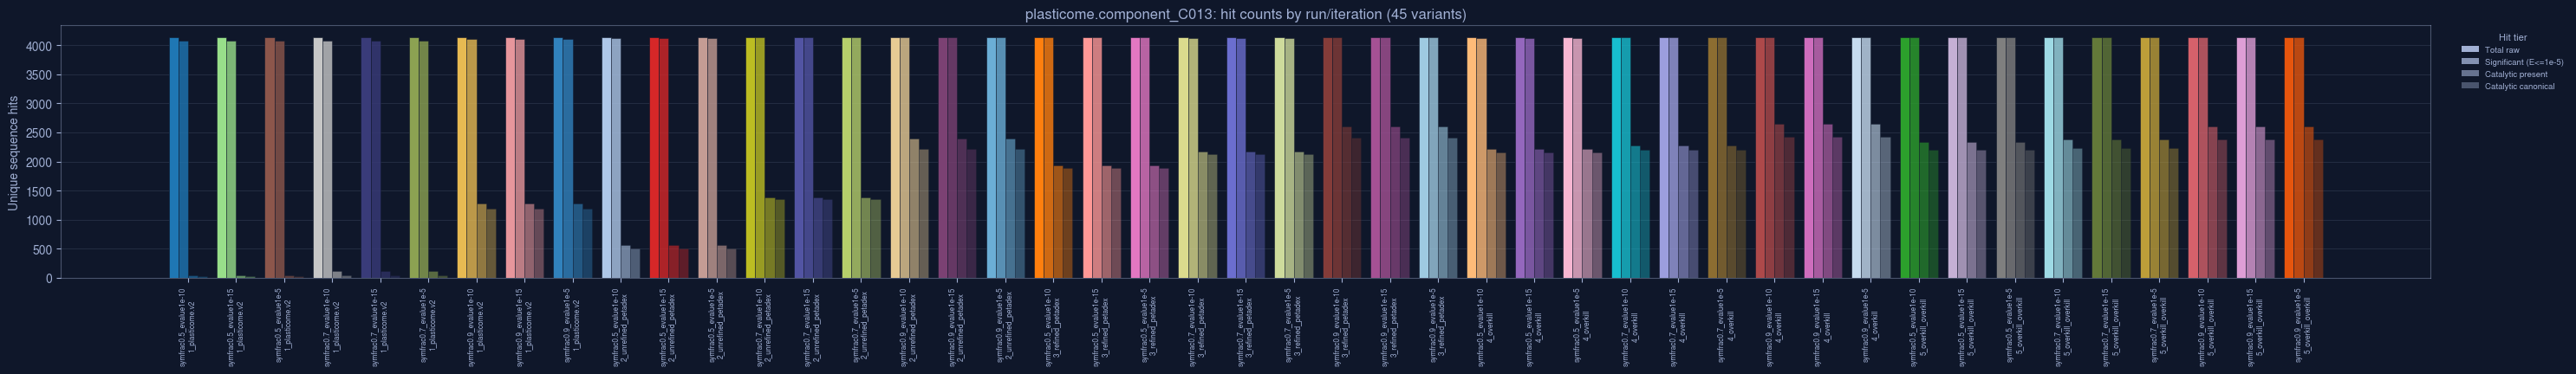

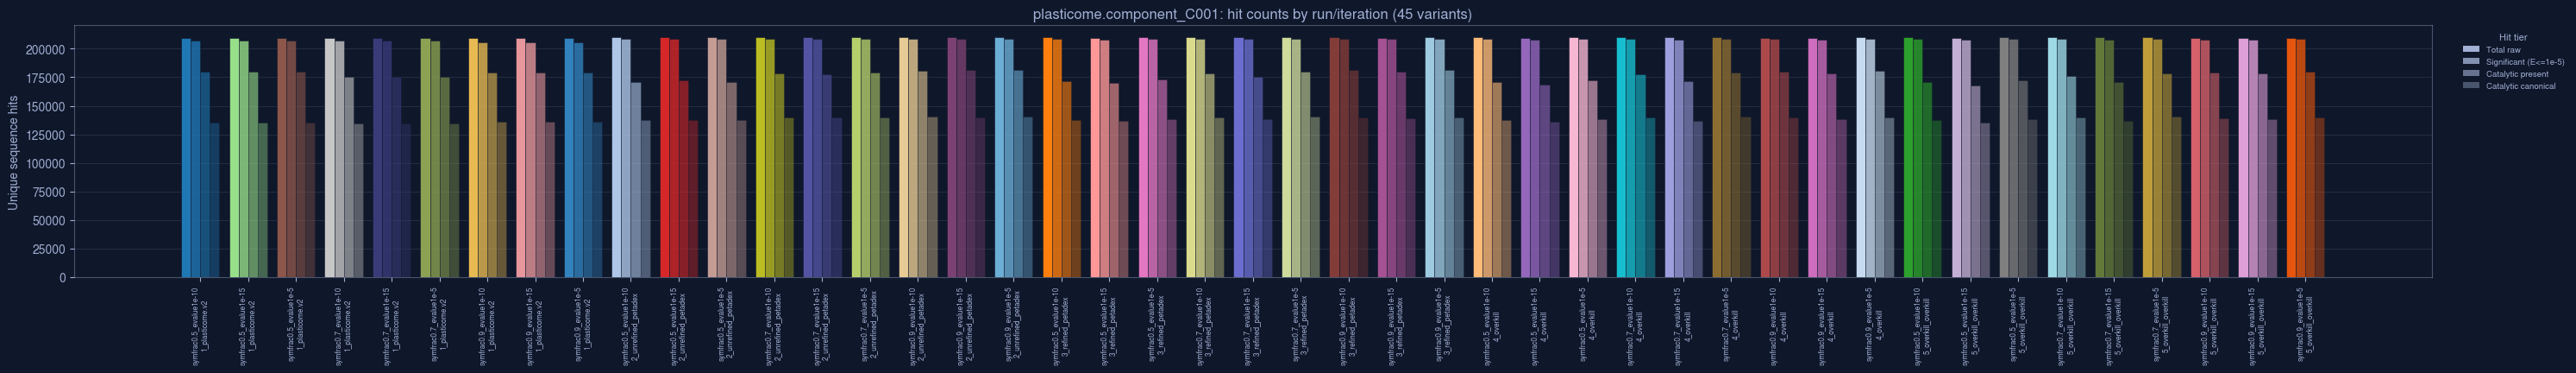

Plotted 4 / 4 sub-components
Saved grouped bar plots to ./4_hmm_creation/images/validation_bar_plots


In [2]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #
print("Starting up...")

import csv
import math
import os
import re
from collections import defaultdict

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ─── INPUT  ─── #
SUMMARY_CSV = "./4_hmm_creation/working/hmm_validation/working/summary.csv"

# ─── OUTPUT ─── #
BAR_PLOT_DIR = "./4_hmm_creation/images/validation_bar_plots"
os.makedirs(BAR_PLOT_DIR, exist_ok=True)

INLINE_SAMPLE_COUNT = 2  # number of sub-components displayed inline; the rest are saved-only

# ─── PLOT STYLE ─── #
BACKGROUND_COLOR = "#0f172a"
TEXT_COLOR = "#a1b0d4"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "Nimbus Sans", "DejaVu Sans"]

BAR_METRICS = [
    ("total_raw_sequence_hits", "Total raw"),
    ("significant_sequence_hits", "Significant (E<=1e-5)"),
    ("catalytic_present_sequence_hits", "Catalytic present"),
    ("catalytic_canonical_sequence_hits", "Catalytic canonical"),
]

# ───────────────────────────────────────────── #
# SET COLOURS FOR HMMS AND SORT THE INPUT TABLE #
# ───────────────────────────────────────────── #

def build_categorical_palette(n):
    """
    MAKES COLOUR PALETTES FOR THE DIFFERENT CATEGORIES OF BAR PLOTS
    """
    swatches = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors) + list(plt.get_cmap("tab20c").colors)
    return [swatches[i % len(swatches)] for i in range(n)]


def iteration_sort_key(iteration_name):
    """
    GRABS STARTING INT TO SORT ITERATIONS ON X-AXIS
    """
    match = re.match(r"\s*(\d+)", iteration_name)
    return int(match.group(1)) if match else float("inf")

# ─── READ INPUT SUMMARY CSV  ─── #
rows_by_subcomponent = defaultdict(list)  # hmm_name -> [row, row, ...]
with open(SUMMARY_CSV, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        rows_by_subcomponent[row["hmm_name"]].append(row)

print(f"Loaded summary rows for {len(rows_by_subcomponent):,} sub-components from {SUMMARY_CSV}")

# ─── COLOUR MAPPING  ─── #
all_variant_keys = sorted({
    (row["run_label"], row["iteration_name"])
    for rows in rows_by_subcomponent.values()
    for row in rows
})
variant_color = dict(zip(all_variant_keys, build_categorical_palette(len(all_variant_keys))))
print(f"Unique (run_label, iteration_name) variants: {len(all_variant_keys):,}")

# ─── SET WHICH COMPONENT TO PRINT  ─── #
inline_sample_hmm_names = set(sorted(rows_by_subcomponent.keys())[:INLINE_SAMPLE_COUNT])

# ───────────────── #
# PLOT THE HMM HITS #
# ───────────────── #

def plot_bar_group(hmm_name, rows, out_path, show=False):
    """
    GROUPED BAR PLOT OF HMM HITS FOR EACH ITERATION,
    E-VALUE CUTOFF AND SYMFRAC VALUE
    """
    variant_rows = sorted(rows, key=lambda r: (iteration_sort_key(r["iteration_name"]), r["run_label"]))
    n_metrics = len(BAR_METRICS)
    bar_width = 0.8 / n_metrics
    group_positions = list(range(len(variant_rows)))

    fig, ax = plt.subplots(figsize=(max(8, len(variant_rows) * 0.9), 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    for metric_idx, (field, label) in enumerate(BAR_METRICS):
        offsets = [pos + (metric_idx - (n_metrics - 1) / 2) * bar_width for pos in group_positions]
        values = [int(row[field]) for row in variant_rows]
        colors = [variant_color[(row["run_label"], row["iteration_name"])] for row in variant_rows]
        alpha = 1.0 - 0.2 * metric_idx
        ax.bar(offsets, values, width=bar_width, color=colors, alpha=alpha,
               edgecolor=BACKGROUND_COLOR, linewidth=0.4, zorder=3)

    variant_labels = [f"{row['run_label']}\n{row['iteration_name']}" for row in variant_rows]
    ax.set_xticks(group_positions)
    ax.set_xticklabels(variant_labels, rotation=90, fontsize=6, color=TEXT_COLOR)

    ax.set_ylabel("Unique sequence hits", color=TEXT_COLOR)
    ax.set_title(f"{hmm_name}: hit counts by run/iteration ({len(variant_rows)} variants)", color=TEXT_COLOR)

    ax.tick_params(colors=TEXT_COLOR)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.4)
    ax.grid(True, axis="y", color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    tier_legend_handles = [
        Patch(facecolor=TEXT_COLOR, edgecolor="none", alpha=1.0 - 0.2 * i, label=label)
        for i, (field, label) in enumerate(BAR_METRICS)
    ]
    tier_legend = ax.legend(
        handles=tier_legend_handles, title="Hit tier", loc="upper left",
        bbox_to_anchor=(1.01, 1.0), fontsize=7, title_fontsize=8,
        frameon=False, labelcolor=TEXT_COLOR,
    )
    tier_legend.get_title().set_color(TEXT_COLOR)

    fig.subplots_adjust(right=0.8, bottom=0.35)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


# ─── PLOT EVERY SUB-COMPONENT (SAVE ALL, DISPLAY ONLY THE SAMPLE) ─── #
n_plotted = 0
for hmm_name, rows in rows_by_subcomponent.items():
    n_plotted += 1
    if n_plotted % 10 == 0:
        print(f"\rPlotted {n_plotted:,} / {len(rows_by_subcomponent):,} sub-components", end="", flush=True)

    safe_name = hmm_name.replace("|", "_").replace("/", "_")
    show = hmm_name in inline_sample_hmm_names

    plot_bar_group(hmm_name, rows, os.path.join(BAR_PLOT_DIR, f"{safe_name}.png"), show=show)

print(f"\rPlotted {n_plotted:,} / {len(rows_by_subcomponent):,} sub-components")
print(f"Saved grouped bar plots to {BAR_PLOT_DIR}")


**RESULTS:**
- C001: Every HMM created is identical.
- C013: 0.9 coverage is the best option, 4th iteration is the best.
- C041: Every HMM created is identical.
- C045: 0.7 coverage is the best option, 5th iteration is the best.

There was no real difference in e-values, and so I will chose 1.0E-10 as the e-value cutoff, as it it's in the middle of the pack and matches the DIAMONd e-value cutoff to enter the HMM.

Since it's not clear if 0.9 or 0.7 symfrac is better, or which iteration is better, I am going to test all the components on these hyperparamers.

### 2.4. In-depth benchmarking for symfrac 0.7 and 0.9
---
I am going to repeat the steps in 2.3. (with different plots and structral analyses) on all of the components now, but keeping symfrac at 0.7 and 0.9 (e-value cutoff 1.0-10, all 5 iterations). I want to see how iterations effects the different symfrac values of the HMMs, in terms of envelope creep and overfitting.

In [83]:
%%bash
set -e

# ───────────────────────────────────── #
# TWO PARAMETER COMPARISON ON MORE HMMS #
# ───────────────────────────────────── #
MASTER_DIRECTORY="./4_hmm_creation/working/draft_depth_hmm_training" # wiped + reused for every sweep run — safe, nothing here needs to survive between runs
FLAT_HMM_DIRECTORY="./4_hmm_creation/working/draft_depth_hmm_training/hmms" # accumulates across every sweep run — never wiped by the script itself

TRAINING_DIR="./4_hmm_creation/input/test_sets"
PLASTICOME_V2_MSA_DIR="../s3/3_msa_cleaning/plasticome_msas"
ANNOTATIONS="../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv"

BUILD_HMM_SCRIPT="../s3/4_hmm_creation/scripts/iterative_hmmbuild-260716.sh"
TRANSFER_SCRIPT="../s3/4_hmm_creation/scripts/iterative_hmmbuild-260716.transfer_annotations.py"
PARSE_SCRIPT="../s3/4_hmm_creation/scripts/iterative_hmmbuild-260716.build_msas.py"

NCBI_SIZE=1101054423
ITERATIONS="1_plasticome.v2,2_unrefined_petadex,3_refined_petadex,4_overkill,5_overkill_overkill" # 5 iterations to see which is the best

# ─── DIFFERENT E-VALUE CUTOFFS AND SYMFRAC VALUES TO BENCHMARK ─── #
COMBOS=(
  "0.7 1e-10"
  "0.9 1e-10"
)

# ─── START THIS SWEEP CLEAN ─── #
rm -rf -- "${FLAT_HMM_DIRECTORY}"
mkdir -p -- "${FLAT_HMM_DIRECTORY}"

for combo in "${COMBOS[@]}"; do
  read -r symfrac evalue <<< "${combo}"
  run_label="symfrac${symfrac}_evalue${evalue}"

  echo "=== Sweep run: ${run_label} ==="

  # ─── RUN PIPELINE ─── #
  bash "${BUILD_HMM_SCRIPT}" \
    --transfer-script "${TRANSFER_SCRIPT}" \
    --parse-script "${PARSE_SCRIPT}" \
    --master-directory "${MASTER_DIRECTORY}" \
    --flat-hmm-directory "${FLAT_HMM_DIRECTORY}" \
    --run-label "${run_label}" \
    --iterations "${ITERATIONS}" \
    --component-database-directory "${TRAINING_DIR}" \
    --total-search-size "${NCBI_SIZE}" \
    --input-msas-path "${PLASTICOME_V2_MSA_DIR}" \
    --reference-annotations "${ANNOTATIONS}" \
    --symfrac "${symfrac}" \
    --e-value-cutoff "${evalue}"
done

=== Sweep run: symfrac0.7_evalue1e-10 ===


2026-09-13 17:55:36 # =========================================== #
2026-09-13 17:55:36 Sun Sep 13 05:55:36 PM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-09-13 17:55:36 # =========================================== #
2026-09-13 17:55:36 # =========================================== #
2026-09-13 17:55:36 Sun Sep 13 05:55:36 PM UTC 2026 Starting iteration 1_plasticome.v2
2026-09-13 17:55:36 # =========================================== #
2026-09-13 18:26:40 1_plasticome.v2: all 53 job(s) completed successfully
2026-09-13 18:26:40 # =========================================== #
2026-09-13 18:26:40 Sun Sep 13 06:26:40 PM UTC 2026 Starting iteration 2_unrefined_petadex
2026-09-13 18:26:40 # =========================================== #
2026-09-13 18:43:35 2_unrefined_petadex: all 53 job(s) completed successfully
2026-09-13 18:43:35 # =========================================== #
2026-09-13 18:43:35 Sun Sep 13 06:43:35 PM UT

=== Sweep run: symfrac0.9_evalue1e-10 ===


2026-09-13 19:35:02 # =========================================== #
2026-09-13 19:35:02 Sun Sep 13 07:35:02 PM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-09-13 19:35:02 # =========================================== #
2026-09-13 19:35:02 # =========================================== #
2026-09-13 19:35:02 Sun Sep 13 07:35:02 PM UTC 2026 Starting iteration 1_plasticome.v2
2026-09-13 19:35:02 # =========================================== #
2026-09-13 20:02:10 1_plasticome.v2: all 53 job(s) completed successfully
2026-09-13 20:02:10 # =========================================== #
2026-09-13 20:02:10 Sun Sep 13 08:02:10 PM UTC 2026 Starting iteration 2_unrefined_petadex
2026-09-13 20:02:10 # =========================================== #
2026-09-13 20:18:08 2_unrefined_petadex: all 53 job(s) completed successfully
2026-09-13 20:18:08 # =========================================== #
2026-09-13 20:18:08 Sun Sep 13 08:18:08 PM UT

### 2.4.1. Search the symfrac 0.7 and 0.9 HMMs
---
Same as 2.3.1, just searching the HMMs we just build against their own components.

In [1]:
%%bash

# ────────────────── #
# VALIDATE THE HMMS  #
# ────────────────── #
MASTER_DIRECTORY="./4_hmm_creation/working/hmm_validation_depth"

VALIDATION_DIR="./4_hmm_creation/input/validation_sets"
PLASTICOME_HMMS="./4_hmm_creation/working/draft_depth_hmm_training/hmms"
ANNOTATIONS="../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv"

SEARCH_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.sh"
TRANSFER_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.transfer_annotations.py"
PARSE_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.parse_output.py"

NCBI_SIZE=1101054423

bash "${SEARCH_SCRIPT}" \
  --transfer-script "${TRANSFER_SCRIPT}" \
  --parse-script "${PARSE_SCRIPT}" \
  --master-directory "${MASTER_DIRECTORY}" \
  --input-hmms-path "${PLASTICOME_HMMS}" \
  --component-database-directory "${VALIDATION_DIR}" \
  --total-search-size "${NCBI_SIZE}" \
  --reference-annotations "${ANNOTATIONS}"


2026-09-14 01:15:33 # =========================================== #
2026-09-14 01:15:34 Mon Sep 14 01:15:33 AM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-09-14 01:15:34 # =========================================== #
2026-09-14 01:15:34 # =========================================== #
2026-09-14 01:15:34 Mon Sep 14 01:15:34 AM UTC 2026 Starting HMM validation search
2026-09-14 01:15:34 # =========================================== #
2026-09-14 01:53:22 all 530 job(s) completed successfully
2026-09-14 01:53:22 # =========================================== #
2026-09-14 01:53:22 Mon Sep 14 01:53:22 AM UTC 2026 All HMMs searched!
2026-09-14 01:53:22 # =========================================== #


### 2.4.2. Visualize the symfrac 0.7 and 0.9 quality
---
This code block will create the same plots from 2.3.2, but with the added an added e-value distribution plot. This is where we can if the further iterations create a bimodal distribution in the hits (splits between hits more and less similar to the input query). This distribution may be okay, as these HMMs will create a distinct divide between close homologs are far homologs, and we may only want to keep closer homologs to search into Logan.

Starting up...
Loaded summary rows for 53 sub-components from ./4_hmm_creation/working/hmm_validation_depth/working/summary.csv
Unique (run_label, iteration_name) variants: 10
Plotted 20 / 53 sub-components

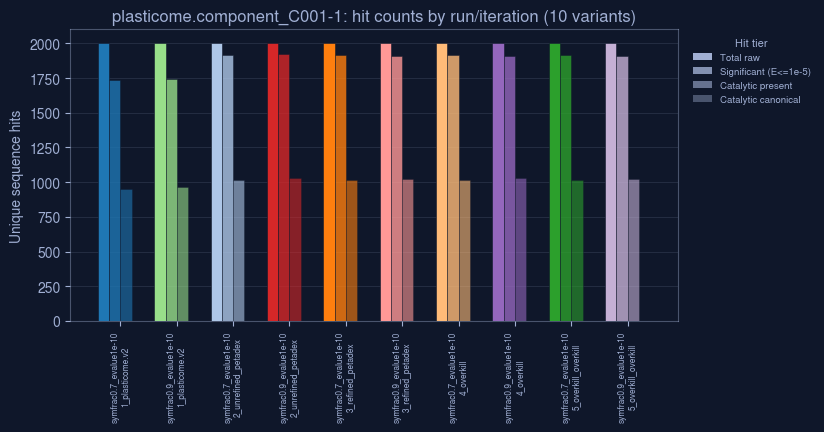

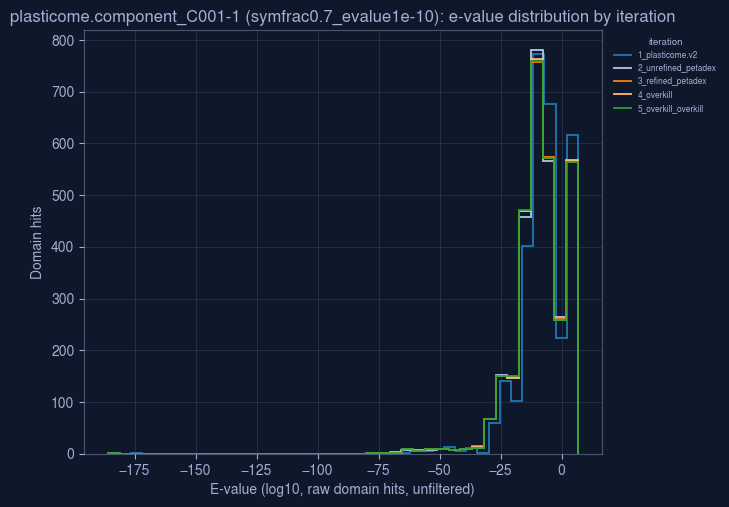

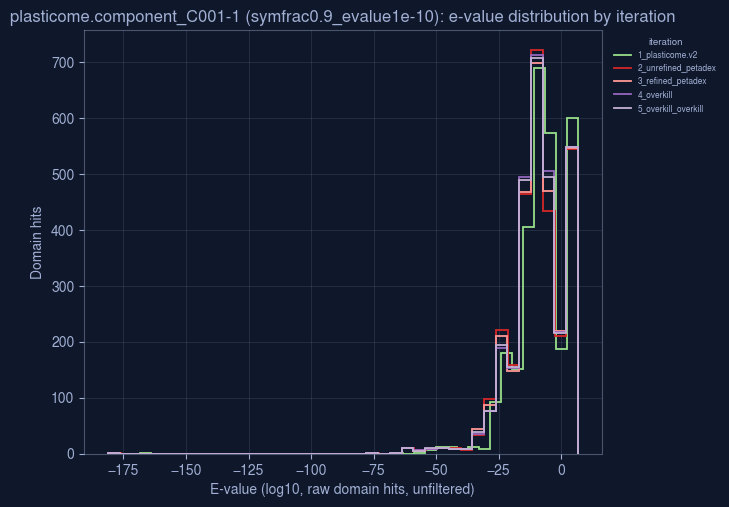

Plotted 50 / 53 sub-components

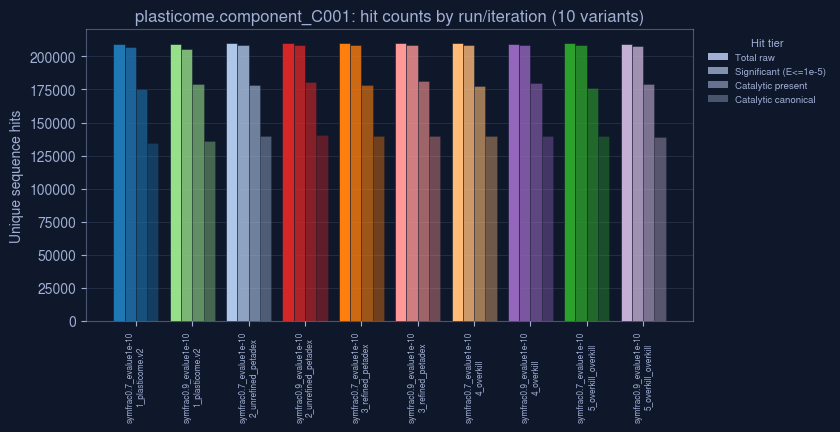

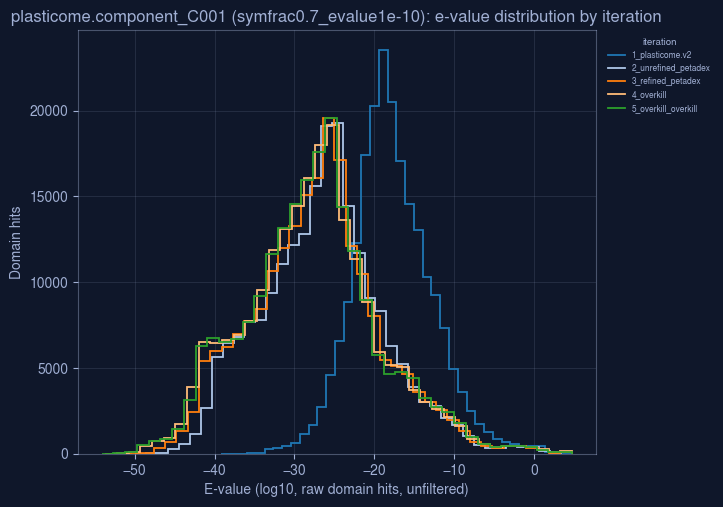

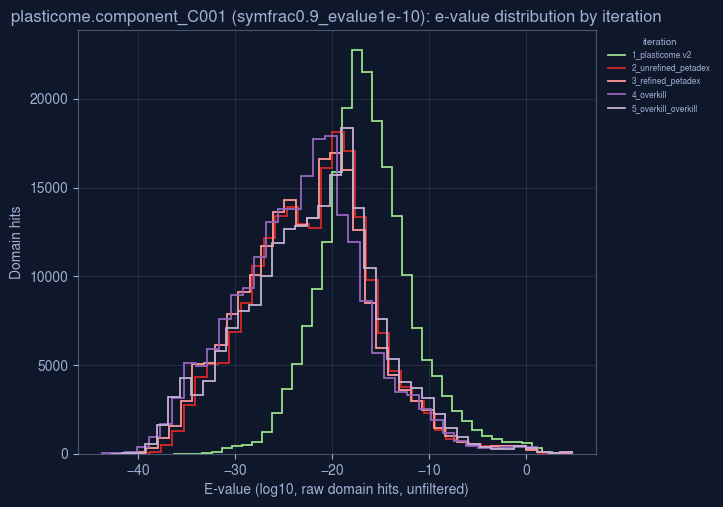

Plotted 53 / 53 sub-components
Saved grouped bar plots to ./4_hmm_creation/images/validation_depth_bar_plots
Saved e-value histograms to ./4_hmm_creation/images/validation_depth_evalue_histograms


In [2]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #
print("Starting up...")

import csv
import math
import os
import re
from collections import defaultdict

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# ─── INPUT ─── #
SUMMARY_CSV = "./4_hmm_creation/working/hmm_validation_depth/working/summary.csv"
EVALUES_DIR = "./4_hmm_creation/working/hmm_validation_depth/working/analysis/evalues"  # {hmm_key}.csv

# ─── OUTPUT ─── #
BAR_PLOT_DIR = "./4_hmm_creation/images/validation_depth_bar_plots"
EVAL_HISTOGRAM_DIR = "./4_hmm_creation/images/validation_depth_evalue_histograms"
os.makedirs(BAR_PLOT_DIR, exist_ok=True)
os.makedirs(EVAL_HISTOGRAM_DIR, exist_ok=True)

INLINE_SAMPLE_COUNT = 2  # number of sub-components displayed inline; the rest are saved-only

# ─── PLOT STYLE (matches dataset_generation/2_nr_search.ipynb) ─── #
BACKGROUND_COLOR = "#0f172a"
TEXT_COLOR = "#a1b0d4"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "Nimbus Sans", "DejaVu Sans"]

BAR_METRICS = [
    ("total_raw_sequence_hits", "Total raw"),
    ("significant_sequence_hits", "Significant (E<=1e-5)"),
    ("catalytic_present_sequence_hits", "Catalytic present"),
    ("catalytic_canonical_sequence_hits", "Catalytic canonical"),
]


def build_categorical_palette(n):
    # tab20 + tab20b + tab20c gives 60 visually distinct swatches, matplotlib's
    # standard trick for coloring many categories
    swatches = list(plt.get_cmap("tab20").colors) + list(plt.get_cmap("tab20b").colors) + list(plt.get_cmap("tab20c").colors)
    return [swatches[i % len(swatches)] for i in range(n)]


def iteration_sort_key(iteration_name):
    # iteration names are e.g. "1_plasticome.v2", "2_unrefined_petadex" — sort
    # by the leading iteration number, not alphabetically (which would put
    # "10_..." before "2_..."), tolerating stray leading whitespace.
    match = re.match(r"\s*(\d+)", iteration_name)
    return int(match.group(1)) if match else float("inf")


# ─── READ MASTER SUMMARY CSV, GROUPED BY SUB-COMPONENT (hmm_name) ─── #
rows_by_subcomponent = defaultdict(list)  # hmm_name -> [row, row, ...]
with open(SUMMARY_CSV, newline="") as f:
    reader = csv.DictReader(f)
    for row in reader:
        rows_by_subcomponent[row["hmm_name"]].append(row)

print(f"Loaded summary rows for {len(rows_by_subcomponent):,} sub-components from {SUMMARY_CSV}")

# ─── SHARED (run_label, iteration_name) -> COLOR MAPPING, CONSISTENT ACROSS EVERY PLOT ─── #
all_variant_keys = sorted({
    (row["run_label"], row["iteration_name"])
    for rows in rows_by_subcomponent.values()
    for row in rows
})
variant_color = dict(zip(all_variant_keys, build_categorical_palette(len(all_variant_keys))))
print(f"Unique (run_label, iteration_name) variants: {len(all_variant_keys):,}")

# ─── PICK A SMALL, DETERMINISTIC INLINE SAMPLE (rest saved-only) ─── #
inline_sample_hmm_names = set(sorted(rows_by_subcomponent.keys())[:INLINE_SAMPLE_COUNT])


def plot_bar_group(hmm_name, rows, out_path, show=False):
    """
    Grouped bar plot for one sub-component: one bar-group per (run_label,
    iteration_name) variant present in `rows` (up to 25), each with up to 4
    bars (BAR_METRICS, sequence-level counts). Same hue per variant, fading
    alpha per metric tier. Groups are ordered by the iteration's leading
    number first, then by run_label, so bars progress 1_..., 2_..., 3_... etc.
    """
    variant_rows = sorted(rows, key=lambda r: (iteration_sort_key(r["iteration_name"]), r["run_label"]))
    n_metrics = len(BAR_METRICS)
    bar_width = 0.8 / n_metrics
    group_positions = list(range(len(variant_rows)))

    fig, ax = plt.subplots(figsize=(max(8, len(variant_rows) * 0.9), 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    for metric_idx, (field, label) in enumerate(BAR_METRICS):
        offsets = [pos + (metric_idx - (n_metrics - 1) / 2) * bar_width for pos in group_positions]
        values = [int(row[field]) for row in variant_rows]
        colors = [variant_color[(row["run_label"], row["iteration_name"])] for row in variant_rows]
        alpha = 1.0 - 0.2 * metric_idx
        ax.bar(offsets, values, width=bar_width, color=colors, alpha=alpha,
               edgecolor=BACKGROUND_COLOR, linewidth=0.4, zorder=3)

    variant_labels = [f"{row['run_label']}\n{row['iteration_name']}" for row in variant_rows]
    ax.set_xticks(group_positions)
    ax.set_xticklabels(variant_labels, rotation=90, fontsize=6, color=TEXT_COLOR)

    ax.set_ylabel("Unique sequence hits", color=TEXT_COLOR)
    ax.set_title(f"{hmm_name}: hit counts by run/iteration ({len(variant_rows)} variants)", color=TEXT_COLOR)

    ax.tick_params(colors=TEXT_COLOR)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.4)
    ax.grid(True, axis="y", color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    tier_legend_handles = [
        Patch(facecolor=TEXT_COLOR, edgecolor="none", alpha=1.0 - 0.2 * i, label=label)
        for i, (field, label) in enumerate(BAR_METRICS)
    ]
    tier_legend = ax.legend(
        handles=tier_legend_handles, title="Hit tier", loc="upper left",
        bbox_to_anchor=(1.01, 1.0), fontsize=7, title_fontsize=8,
        frameon=False, labelcolor=TEXT_COLOR,
    )
    tier_legend.get_title().set_color(TEXT_COLOR)

    fig.subplots_adjust(right=0.8, bottom=0.35)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


def plot_evalue_histogram(hmm_name, run_label, rows, out_path, show=False):
    """
    Overlaid e-value histogram for one sub-component, one parameter combo
    (run_label): one distribution per iteration_name (max 5, since that's
    all the iterations we run), reading each iteration's full raw
    (unfiltered) i_evalue list from EVALUES_DIR/{hmm_key}.csv. Uses unfilled
    "step" histograms (not filled/stacked) so the overlapping distributions
    stay legible.
    """
    fig, ax = plt.subplots(figsize=(9, 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    legend_handles = []
    for row in sorted(rows, key=lambda r: iteration_sort_key(r["iteration_name"])):
        hmm_key = row["hmm_key"]
        evalues_path = os.path.join(EVALUES_DIR, f"{hmm_key}.csv")
        if not os.path.exists(evalues_path):
            continue

        with open(evalues_path, newline="") as f:
            i_evalues = [float(r["i_evalue"]) for r in csv.DictReader(f)]
        if not i_evalues:
            continue

        safe_evalues = [e if e > 0 else 1e-300 for e in i_evalues]
        log_evalues = [math.log10(e) for e in safe_evalues]

        variant_key = (row["run_label"], row["iteration_name"])
        color = variant_color[variant_key]
        ax.hist(log_evalues, bins=40, histtype="step", color=color, linewidth=1.3, zorder=3)
        legend_handles.append(Line2D([0], [0], color=color, lw=1.3, label=row["iteration_name"]))

    ax.set_xlabel("E-value (log10, raw domain hits, unfiltered)", color=TEXT_COLOR)
    ax.set_ylabel("Domain hits", color=TEXT_COLOR)
    ax.set_title(f"{hmm_name} ({run_label}): e-value distribution by iteration", color=TEXT_COLOR)

    ax.tick_params(colors=TEXT_COLOR)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.4)
    ax.grid(True, color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    legend = ax.legend(
        handles=legend_handles, title="iteration", loc="upper left",
        bbox_to_anchor=(1.01, 1.0), fontsize=6, title_fontsize=7,
        frameon=False, labelcolor=TEXT_COLOR,
    )
    legend.get_title().set_color(TEXT_COLOR)

    fig.subplots_adjust(right=0.7)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


# ─── PLOT EVERY SUB-COMPONENT (SAVE ALL, DISPLAY ONLY THE SAMPLE) ─── #
n_plotted = 0
for hmm_name, rows in rows_by_subcomponent.items():
    n_plotted += 1
    if n_plotted % 10 == 0:
        print(f"\rPlotted {n_plotted:,} / {len(rows_by_subcomponent):,} sub-components", end="", flush=True)

    safe_name = hmm_name.replace("|", "_").replace("/", "_")
    show = hmm_name in inline_sample_hmm_names

    plot_bar_group(hmm_name, rows, os.path.join(BAR_PLOT_DIR, f"{safe_name}.png"), show=show)

    # ─── ONE E-VALUE HISTOGRAM PER PARAMETER COMBO (run_label), EACH CAPPED AT 5 ITERATION DISTRIBUTIONS ─── #
    rows_by_run_label = defaultdict(list)
    for row in rows:
        rows_by_run_label[row["run_label"]].append(row)

    for run_label, run_rows in sorted(rows_by_run_label.items()):
        safe_run_label = run_label.replace("|", "_").replace("/", "_")
        plot_evalue_histogram(
            hmm_name, run_label, run_rows,
            os.path.join(EVAL_HISTOGRAM_DIR, f"{safe_name}__{safe_run_label}.png"),
            show=show,
        )

print(f"\rPlotted {n_plotted:,} / {len(rows_by_subcomponent):,} sub-components")
print(f"Saved grouped bar plots to {BAR_PLOT_DIR}")
print(f"Saved e-value histograms to {EVAL_HISTOGRAM_DIR}")


**RESULTS:**
1. Iteration comments: if a component is not mentioned in this list, that means the iteration had no real difference.
- C004,C005,C006,C012,C014-3 = iteration 2 plateau
- C013,C014-1,C029,C009,C011 = iteration 3 plateau
- C014-2 = iteration 4 plateau
- C008 = decreases in quality after 2
- C035, C045 = 5 is best
2. Symfrac comments: if a component is not mentioned in this list, that means the symfrac didn't change much
- C009,C045 = 0.7 slightly better
- C019, C020, C029 = 0.9 is slightly better
- C008, C011 = 0.7 better
- C035 = 0.9 better
3. Bad HMMs?
- C001-1,C003,C008,C010,C023 = okay (more than half are fragments)
- C001-2,C006-1,C009,C014,C018,C027,C028 = bad (missing fragment hits)

### 2.4.3. Create per-component fastaas of the test structures
---
We are now testing out to see if the HMMs start and end ranges correspond correctly to the domain splitting by AFRAGMENTER. To do this, we are going to run HMMsearch against test structure fastaas.

This codeblock retrieves the accessions from the cutsites csv, and subsets the component fastaas to only include those accessions. The accessions are not 100% matches, as it seems Alex removed the .1 suffix on a few of them.

Additionally, an issue with the cutsites csv is that it does not say which amino acids the protein ends and starts on. We need that for % domain hit.

In [22]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #
print("Starting up...")

import csv
import os
import re
from collections import defaultdict

# ─── INPUT ─── #
CUTSITES_CSV = "./4_hmm_creation/working/structure_analysis/test-set_cutsites.csv"
"""
component_id,matched_accession,aa_positions_of_cutsites
ex.
C001,CAB3929344,"12,314"
"""

NR_HITS = "../s3/2_nr_search/petadex-nr.v260701.significant-hits.fastaa"
"""
>genbank_accession:genbank_accession:ect|e_value|pid|bitscore|query_petadex_id|component_id
ex.
>WP_305403363.1|7.24e-11|23.5|73.6|PL181|C034
MNLHYQVEGDGKTIILIHGLFGSAANLGLLARSLKNKYKVISVDLRNHGLSPH
"""

# ─── OUTPUT ─── #
STRUCTURE_TESTSET_FASTAAS = "./4_hmm_creation/working/structure_analysis/fastaas"
UPDATED_CUTSITES_CSV = "./4_hmm_creation/working/structure_analysis/cleaned.test-set_cutsites.csv"
"""
component_id,genbank_accession,aa_positions_of_cutsites
ex.
C001,CAB3929344.1,"1,12,314,400"
"""

# ───────────────────────────────────────────── #
# CREATE FASTAA OF TEST STRUCTURS PER COMPONENT #
# ───────────────────────────────────────────── #

# ─── READ THE CUTSITES CSV AND GET A LIST OF ACCESSIONS ─── #
with open(CUTSITES_CSV, newline="") as f:
    cutsite_rows = list(csv.DictReader(f))

needed_by_component = defaultdict(set)  # component_id -> {matched_accession, ...}
for row in cutsite_rows:
    needed_by_component[row["component_id"]].add(row["matched_accession"])

print(f"Loaded {len(cutsite_rows):,} cutsite rows across {len(needed_by_component):,} components from {CUTSITES_CSV}")

# ─── READ THE FASTAA AND GET AA SEQUENCES FOR EACH ACCESSION AND PROTEIN LENGTHS ─── #
VERSION_SUFFIX_RE = re.compile(r"\.\d+$")

matched = {}  # (component_id, base_accession) -> (full_accession, sequence)
n_scanned = 0

with open(NR_HITS) as f:
    header = None
    for line in f:
        line = line.rstrip("\n")
        if line.startswith(">"):
            header = line[1:]
            n_scanned += 1
            if n_scanned % 1_000_000 == 0:
                print(f"\rScanned {n_scanned:,} NR-hit records...", end="", flush=True)
            continue

        # header is "accession_field|e_value|pid|bitscore|query_petadex_id|component_id" —
        # accession_field (everything before the last 5 fields) may itself contain "|" or
        # "," for merged NR duplicate entries, e.g. "CAA29171.1,prf||1307202B", so split
        # from the right rather than assuming accession is field[0]
        parts = header.split("|")
        component_id = parts[-1]
        if component_id not in needed_by_component:
            continue

        accession_field = "|".join(parts[:-5])
        sequence = line

        for candidate in accession_field.split(","):
            base_accession = VERSION_SUFFIX_RE.sub("", candidate)
            key = (component_id, base_accession)
            if base_accession in needed_by_component[component_id] and key not in matched:
                matched[key] = (candidate, sequence)

print(f"\rScanned {n_scanned:,} NR-hit records")
print(f"Matched {len(matched):,} / {sum(len(v) for v in needed_by_component.values()):,} needed accessions")

# ─── CREATE THE PER-COMPONENT FASTAAS ─── #
os.makedirs(STRUCTURE_TESTSET_FASTAAS, exist_ok=True)

for component_id, matched_accessions in needed_by_component.items():
    out_path = os.path.join(STRUCTURE_TESTSET_FASTAAS, f"{component_id}.fastaa")
    with open(out_path, "w") as f:
        for matched_accession in sorted(matched_accessions):
            key = (component_id, matched_accession)
            if key not in matched:
                continue
            accession, sequence = matched[key]
            f.write(f">{accession}\n{sequence}\n")

print(f"Wrote per-component fastaas to {STRUCTURE_TESTSET_FASTAAS}")

# ─── REMAKE THE CUTSITES CSV WITH THE CORRECT ACCESSION AND THE START AND END OF THE PROTEIN IN THE AA POSITIONS ─── #
updated_rows = []
missing_rows = []

for row in cutsite_rows:
    component_id = row["component_id"]
    key = (component_id, row["matched_accession"])
    if key not in matched:
        missing_rows.append(row)
        continue

    accession, sequence = matched[key]
    protein_length = len(sequence)
    interior_positions = [int(p) for p in row["aa_positions_of_cutsites"].split(",")]
    boundaries = [1] + interior_positions + [protein_length]

    updated_rows.append({
        "component_id": component_id,
        "genbank_accession": accession,
        "aa_positions_of_cutsites": ",".join(str(p) for p in boundaries),
    })

with open(UPDATED_CUTSITES_CSV, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["component_id", "genbank_accession", "aa_positions_of_cutsites"])
    writer.writeheader()
    writer.writerows(updated_rows)

print(f"Wrote {len(updated_rows):,} updated cutsite rows to {UPDATED_CUTSITES_CSV}")
if missing_rows:
    print(f"WARNING: {len(missing_rows):,} cutsite row(s) had no matching sequence in {NR_HITS}:")
    for row in missing_rows:
        print(f"  {row['component_id']}, {row['matched_accession']}")

Starting up...
Loaded 36,321 cutsite rows across 46 components from ./4_hmm_creation/working/structure_analysis/test-set_cutsites.csv
Scanned 7,825,107 NR-hit records...
Matched 36,315 / 36,321 needed accessions
Wrote per-component fastaas to ./4_hmm_creation/working/structure_analysis/fastaas
Wrote 36,315 updated cutsite rows to ./4_hmm_creation/working/structure_analysis/cleaned.test-set_cutsites.csv
  C001, WP_173061649
  C001, ADM47605
  C002, AAA33335
  C008, AAD22743
  C011, WP_085748997
  C024, AAR25849


### 2.4.4. Search against the structure fastaas
---
This codeblock searchs the structure test set fastaas and returns where the HMM hit ranges are. Same pipeline as previous HMMsearchs.

In [3]:
%%bash

# ────────────────── #
# VALIDATE THE HMMS  #
# ────────────────── #
MASTER_DIRECTORY="./4_hmm_creation/working/structure_analysis/hmm_search"

STRUCTURE_TESTSET_FASTAAS="./4_hmm_creation/working/structure_analysis/fastaas"
PLASTICOME_HMMS="./4_hmm_creation/working/draft_depth_hmm_training/hmms"
ANNOTATIONS="../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv"

SEARCH_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.sh"
TRANSFER_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.transfer_annotations.py"
PARSE_SCRIPT="../s3/4_hmm_creation/scripts/hmmsearch_validation-260822.parse_domain_hits.py"

NCBI_SIZE=1101054423

bash "${SEARCH_SCRIPT}" \
  --transfer-script "${TRANSFER_SCRIPT}" \
  --parse-script "${PARSE_SCRIPT}" \
  --master-directory "${MASTER_DIRECTORY}" \
  --input-hmms-path "${PLASTICOME_HMMS}" \
  --component-database-directory "${STRUCTURE_TESTSET_FASTAAS}" \
  --total-search-size "${NCBI_SIZE}" \
  --reference-annotations "${ANNOTATIONS}"

2026-09-14 01:57:15 # =========================================== #
2026-09-14 01:57:15 Mon Sep 14 01:57:15 AM UTC 2026 Building shared reference fasta from ../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv
2026-09-14 01:57:15 # =========================================== #
2026-09-14 01:57:15 # =========================================== #
2026-09-14 01:57:15 Mon Sep 14 01:57:15 AM UTC 2026 Starting HMM validation search
2026-09-14 01:57:15 # =========================================== #


2026-09-14 01:57:47 all 530 job(s) completed successfully
2026-09-14 01:57:47 # =========================================== #
2026-09-14 01:57:47 Mon Sep 14 01:57:47 AM UTC 2026 All HMMs searched!
2026-09-14 01:57:47 # =========================================== #


### 2.4.5. Visualize the quality of the HMM hit % of the domains
---
This codeblock merges the cut sites table and the HMMsearch output on accession + component_id. This then allows comparison of the HMM hit ranges to the cut sites from AFRAGMENTER.

The first thing that is done is finding which domain (annotated by AFRAGMENTER) is hit by the HMM:
```
Cutsites from AFRAGMENTER declaring 2 domains:
1 ──────── 200 ────────── 500

Case 1: HMM hit range = 10-120
Case 2: HMM hit range = 50-250 # majority of hit is in domain 1
Therefore HMM hit to domain 1.
```
The second thing that is done is calculating the % of the domain that is hit by the HMM:
```
Domain 1 size = 200
HMM hit 1 size = 110 in domain, 0 out domain
HMM hit 1 in range % = 110/200
HMM hit 1 out range % = 0/200

HMM hit 2 size = 150 in domain, 50 out domain
HMM hit 2 in range % = 150/200
HMM hit 2 out range % = 50/200
```

The last thing that is done is to plot % in-range and % out-range as violin plots, one per sub-component + parameter sweep. Each plot has one violin per iteration (the distribution of % across every domain hit in that iteration), and % in-range and % out-range get separate plots. This allows for visualization of how the envelope of the HMM changes with further iterations, and the difference in HMM envelope creep between 0.9 coverage and 0.7 coverage.

Starting up...
Loaded domain boundaries for 36,315 accessions from ./4_hmm_creation/working/structure_analysis/cleaned.test-set_cutsites.csv
Loaded 393,104 domain hits from ./4_hmm_creation/working/structure_analysis/hmm_search/working/summary.csv
  0 hit(s) had no matching cutsites accession
  21,945 hit(s) failed the >50% single-segment coverage criteria (excluded from the violin plots)
Grouped into 92 (component, run_label) combos


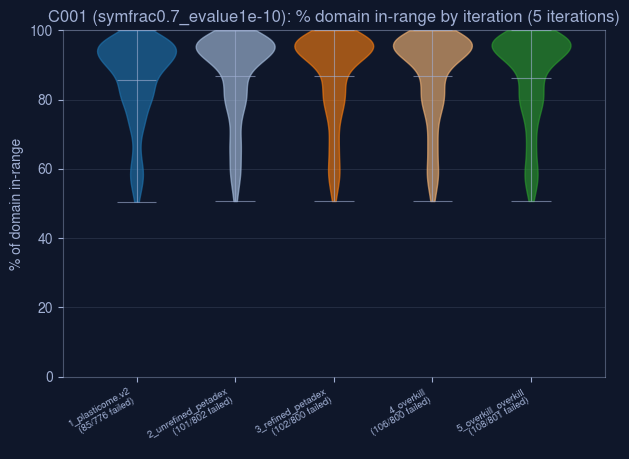

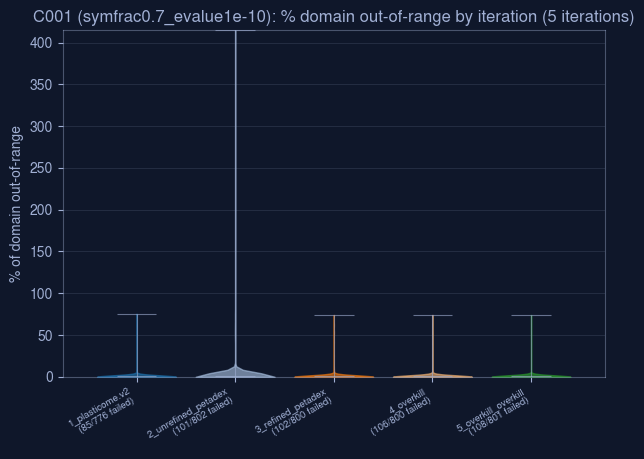

Plotted 40 / 92 groups

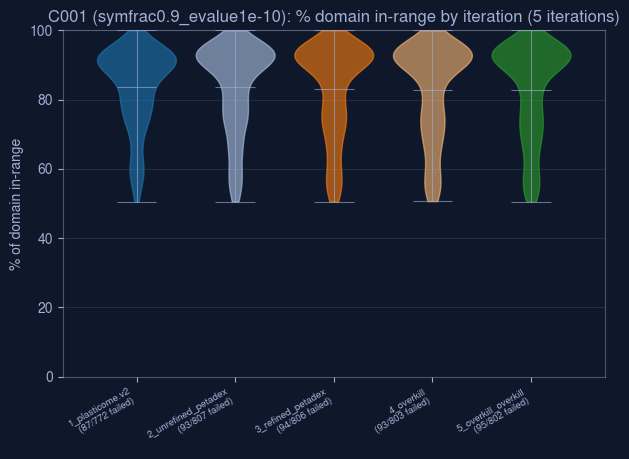

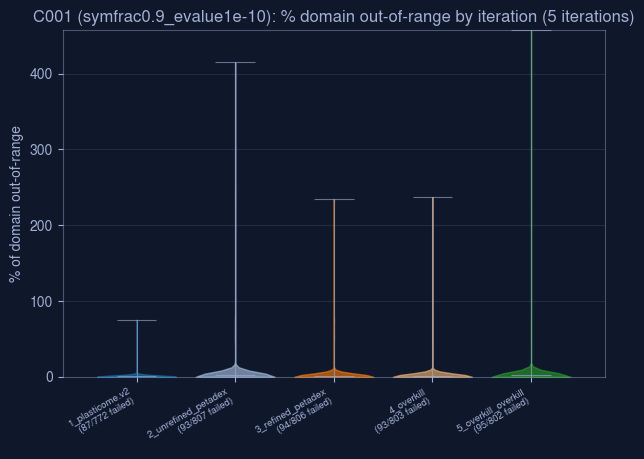

Plotted 92 / 92 groups
Saved % in-range violin plots to ./4_hmm_creation/images/domain_hit_in_range_violin_plots
Saved % out-range violin plots to ./4_hmm_creation/images/domain_hit_out_range_violin_plots


In [4]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #
print("Starting up...")

import csv
import os
import re
from collections import defaultdict

import matplotlib.pyplot as plt

# ─── REUSES GRAPHING PARAMETERS AS ABOVE ─── #

# ─── INPUT ─── #
UPDATED_CUTSITES_CSV = "./4_hmm_creation/working/structure_analysis/cleaned.test-set_cutsites.csv"
DOMAIN_HITS_CSV = "./4_hmm_creation/working/structure_analysis/hmm_search/working/summary.csv"

# ─── OUTPUT ─── #
DOMAIN_IN_VIOLIN_DIR = "./4_hmm_creation/images/domain_hit_in_range_violin_plots"
DOMAIN_OUT_VIOLIN_DIR = "./4_hmm_creation/images/domain_hit_out_range_violin_plots"
os.makedirs(DOMAIN_IN_VIOLIN_DIR, exist_ok=True)
os.makedirs(DOMAIN_OUT_VIOLIN_DIR, exist_ok=True)

INLINE_SAMPLE_COUNT = 2  # number of (component, run_label) groups displayed inline; the rest are saved-only

COVERAGE_THRESHOLD = 0.5  # a cutsite segment "qualifies" for comparison once the HMM hit covers more than this fraction of it

# ─── LOAD CUTSITES AND BUILD PER-ACCESSION DOMAIN BOUNDARY LISTS ─── #
domains_by_key = {}  # (component_id, accession) -> [(start, end), ...]
with open(UPDATED_CUTSITES_CSV, newline="") as f:
    for row in csv.DictReader(f):
        """
        sorted(set(...)) collapses the duplicate boundary that shows up whenever
        AFRAGMENTER's last domain-end cutsite already equals the protein length
        (true for ~88% of rows) — 2.4.3 appends the length unconditionally, so
        without this the terminal "domain" here would have zero length
        """
        boundaries = sorted({int(p) for p in row["aa_positions_of_cutsites"].split(",")})
        domains_by_key[(row["component_id"], row["genbank_accession"])] = list(zip(boundaries[:-1], boundaries[1:]))

print(f"Loaded domain boundaries for {len(domains_by_key):,} accessions from {UPDATED_CUTSITES_CSV}")

# ─── LOAD DOMAIN HITS, DECODE hmm_key, COMPARE EACH HIT AGAINST THE SPAN OF EVERY SEGMENT IT SUBSTANTIALLY COVERS ─── #
""" 
AFRAGMENTER sometimes cuts a single true structural domain into multiple segments at internal
flexible/loop regions, so a real HMM hit can legitimately span more than one cutsite segment.
A segment "qualifies" once the hit covers more than COVERAGE_THRESHOLD of that segment; when
several segments qualify, the hit is benchmarked against the full span from the first
qualifying segment's start to the last qualifying segment's end, not against a single segment.
"""
# results_by_group: (hmm_name, run_label) -> iteration_name -> {"in": [pct, ...], "out": [pct, ...], "failed": n}
results_by_group = defaultdict(lambda: defaultdict(lambda: {"in": [], "out": [], "failed": 0}))
n_hits = 0
n_no_domain_match = 0
n_coverage_failures = 0

with open(DOMAIN_HITS_CSV, newline="") as f:
    for row in csv.DictReader(f):
        n_hits += 1
        component_id = row["component_id"]
        accession = row["accession"]
        hmm_start, hmm_end = int(row["hmm_start"]), int(row["hmm_end"])

        domains = domains_by_key.get((component_id, accession))
        if not domains:
            n_no_domain_match += 1
            continue

        # ─── DECODE hmm_key "{run_label}__{iteration_name}__{alignment_name}" (same convention as hmmsearch_validation-260822.sh) ─── #
        # done before the coverage check so a failing hit still attributes to the right group below
        hmm_key = row["hmm_key"]
        run_label, remainder = hmm_key.split("__", 1)
        iteration_name, alignment_name = remainder.split("__", 1)
        component_token = alignment_name.rsplit("_", 1)[-1]
        suffix_match = re.match(r"^([A-Za-z0-9]+)-[0-9]+$", component_token)
        hmm_name = suffix_match.group(1) if suffix_match else component_token
        group = results_by_group[(hmm_name, run_label)][iteration_name]

        # ─── FIND EVERY SEGMENT THIS HIT COVERS MORE THAN COVERAGE_THRESHOLD OF ─── #
        qualifying_segments = [
            (start, end) for start, end in domains
            if max(0, min(hmm_end, end) - max(hmm_start, start)) / (end - start) > COVERAGE_THRESHOLD
        ]

        if not qualifying_segments:
            group["failed"] += 1
            n_coverage_failures += 1
            continue

        # ─── COMPARE THE HIT AGAINST THE FULL SPAN OF THE QUALIFYING SEGMENTS (RECOMPUTED FRESH, NOT SUMMED PER-SEGMENT) ─── #
        combined_start = min(start for start, _ in qualifying_segments)
        combined_end = max(end for _, end in qualifying_segments)
        combined_len = combined_end - combined_start
        combined_overlap = max(0, min(hmm_end, combined_end) - max(hmm_start, combined_start))
        hit_len = hmm_end - hmm_start
        in_range_pct = combined_overlap / combined_len * 100
        out_range_pct = (hit_len - combined_overlap) / combined_len * 100

        group["in"].append(in_range_pct)
        group["out"].append(out_range_pct)

print(f"Loaded {n_hits:,} domain hits from {DOMAIN_HITS_CSV}")
print(f"  {n_no_domain_match:,} hit(s) had no matching cutsites accession")
print(f"  {n_coverage_failures:,} hit(s) failed the >{COVERAGE_THRESHOLD:.0%} single-segment coverage criteria (excluded from the violin plots)")
print(f"Grouped into {len(results_by_group):,} (component, run_label) combos")

# ─── SHARED iteration_name -> COLOR MAPPING, CONSISTENT ACROSS EVERY PLOT ─── #
all_iteration_names = sorted(
    {iteration_name for iterations in results_by_group.values() for iteration_name in iterations},
    key=iteration_sort_key,
)
iteration_color = dict(zip(all_iteration_names, build_categorical_palette(len(all_iteration_names))))

inline_sample_keys = set(sorted(results_by_group.keys())[:INLINE_SAMPLE_COUNT])


def plot_domain_violin(hmm_name, run_label, iterations, metric_key, metric_label, out_path, show=False):
    """
    Violin plot of % domain {metric_label} for one sub-component + parameter-sweep
    combo: one violin per iteration_name, showing the distribution of that metric
    across every HMM domain hit in that iteration. Colored the same as the
    iteration_name coloring used elsewhere in 2.4. Every iteration's x-tick also
    reports how many structures failed the >50% segment-coverage criteria out of
    how many were tested, so an iteration with a 0% pass rate still appears
    instead of silently vanishing from the plot.
    """
    # include an iteration if it has metric values OR at least one coverage failure to report
    iteration_names = [
        it for it in sorted(iterations, key=iteration_sort_key)
        if iterations[it][metric_key] or iterations[it]["failed"]
    ]
    values = [iterations[it][metric_key] for it in iteration_names]
    positions = list(range(1, len(iteration_names) + 1))

    fig, ax = plt.subplots(figsize=(max(6, len(iteration_names) * 1.4), 5.5), facecolor=BACKGROUND_COLOR)
    ax.set_facecolor(BACKGROUND_COLOR)

    # violinplot can't draw a body for an empty distribution, so only non-empty iterations are
    # passed to it — but every iteration (including 0%-pass ones) still keeps its tick/position
    plot_positions = [pos for pos, vs in zip(positions, values) if vs]
    plot_values = [vs for vs in values if vs]

    if plot_values:
        parts = ax.violinplot(plot_values, positions=plot_positions, showmeans=True, showextrema=True, widths=0.8)

        plotted_names = [it for it, vs in zip(iteration_names, values) if vs]
        for iteration_name, body in zip(plotted_names, parts["bodies"]):
            color = iteration_color[iteration_name]
            body.set_facecolor(color)
            body.set_edgecolor(color)
            body.set_alpha(0.6)

        for part_name in ("cmeans", "cmaxes", "cmins", "cbars"):
            parts[part_name].set_color(TEXT_COLOR)
            parts[part_name].set_alpha(0.6)
            parts[part_name].set_linewidth(0.8)

        y_max = max(100, max(v for vs in plot_values for v in vs))
    else:
        y_max = 100

    if positions:
        ax.set_xticks(positions)
        tick_labels = [
            f"{it}\n({iterations[it]['failed']}/{iterations[it]['failed'] + len(iterations[it][metric_key])} failed)"
            for it in iteration_names
        ]
        ax.set_xticklabels(tick_labels, rotation=30, ha="right", fontsize=7, color=TEXT_COLOR)
        ax.set_xlim(0.25, len(positions) + 0.75)

    ax.set_ylim(0, y_max)
    ax.set_ylabel(f"% of domain {metric_label}", color=TEXT_COLOR)
    ax.set_title(f"{hmm_name} ({run_label}): % domain {metric_label} by iteration ({len(iteration_names)} iterations)", color=TEXT_COLOR)

    ax.tick_params(colors=TEXT_COLOR)
    for spine in ax.spines.values():
        spine.set_color(TEXT_COLOR)
        spine.set_alpha(0.4)
    ax.grid(True, axis="y", color=TEXT_COLOR, alpha=0.2, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    fig.subplots_adjust(bottom=0.25)
    plt.savefig(out_path, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


# ─── ONE IN-RANGE AND ONE OUT-RANGE VIOLIN PLOT PER (COMPONENT, RUN_LABEL) GROUP (SAVE ALL, DISPLAY ONLY THE SAMPLE) ─── #
METRICS = [
    ("in", "in-range", DOMAIN_IN_VIOLIN_DIR),
    ("out", "out-of-range", DOMAIN_OUT_VIOLIN_DIR),
]

n_plotted = 0
for (hmm_name, run_label), iterations in results_by_group.items():
    n_plotted += 1
    if n_plotted % 10 == 0:
        print(f"\rPlotted {n_plotted:,} / {len(results_by_group):,} groups", end="", flush=True)

    safe_name = hmm_name.replace("|", "_").replace("/", "_")
    safe_run_label = run_label.replace("|", "_").replace("/", "_")
    show = (hmm_name, run_label) in inline_sample_keys

    for metric_key, metric_label, out_dir in METRICS:
        plot_domain_violin(
            hmm_name, run_label, iterations, metric_key, metric_label,
            os.path.join(out_dir, f"{safe_name}__{safe_run_label}.png"),
            show=show,
        )

print(f"\rPlotted {n_plotted:,} / {len(results_by_group):,} groups")
print(f"Saved % in-range violin plots to {DOMAIN_IN_VIOLIN_DIR}")
print(f"Saved % out-range violin plots to {DOMAIN_OUT_VIOLIN_DIR}")

**RESULTS:**
1. Iteration comments for domain % in: if a component is not mentioned in this list, that means the iteration had no real difference.
- C001,C004,C011 = plateau after 2
- C002 = 5 bad, 4 good
- C008 = plateau bad for 0.7 after 1, 0.9 steadily improve with 5 being good
- C010 = plateau after 3 for 0.7, after 2 for 0.9
- C012 = 3 and 4 for 0.9 is worse, 2 and 2 and 4 and 5 for 0.7 is worse
- C020 = for 0.7 2 is good then gets worse, for 0.9 after 2 is good
- C023 = for 0.9 2, 3, 5 are very good, 1 and 3 are bad
- C024 = 4 and 5 are good for 0.7, 0.9 same
- C031 = 4 and 5 decrease for 0.7, 0.9 same
- C032 = 0.9 good after 2, 0.7 good after 3
2. Symfrac comments for domain % in: if a component is not mentioned in this list, that means the symfrac didn't change much
- C001,C007 = 0.7 slightly better
- C002,C018,C020 = 0.9 slightly better
- C009,C024,C041 = 0.7 better
- C005,C011,C031,C033 = 0.9 better
- C015 = 0.7 much better
- C008,C023 = 0.9 much better
3. HMM quality for % in: if a component is not mentioned it's about 90% domain hit
- C001,C012,C026,C028,C039 = ~80% average
- C014,C027 = ~ 70% average
- C015 = ~50% average
4. Iteration comments for domain % out: if a component is not mentioned in this list, that means the iteration had no real difference.
- C004,C008,C012,C019,C024,C032 = slightly worse over iterations
5. Symfrac comments for domain % out: if a component is not mentioned in this list, that means the symfrac didn't change much
- C008,C011,C023,C033 = 0.9 better
- C009,C019 = 0.7 slightly better
- C015 = 0.7 way better
6. HMM quality for % in: if a component is not mentioned it's about 110% domain hit
- C006 = ~25% out but bimodal around 0 and 50
- C008 = ~30% out

Generally almost all average at about 10% out or less, but a most have a few straglers that hit to a lot of the protein outside the catalytic domain (C14 for example has 1400%, although this is an error from AFRAGMENTER).
--> afragmenter put a cutsite in the middle of the catalytic domain (like 5 residues) and the HMM only hit to less than 40% of the entire catalytic domain, so the 5 residue insert became the "catalytic domain" to measure against. I could fix this up through fixing up the parameters used for AFRAGMENTER, but I don't think it's worth the time.

### 2.5. Final hyper parameters
---
**SYMFRAC:**
- There seems to be no significant difference between symfrac 0.7 and 0.9, both achieving about the same # of catalytically complete hits and total hits, and seeems to be hitting about the same regions across the board. The main difference is that 0.9 symfrac fails for C015, while 0.7 works. Therefore I will chose 0.7 symfrac moving forward.

**ITERATION:**
- There seems to be little difference between iteration 3 through 5, although there apepars to be slightly negative effects associated with iteration 5 (reducing hits; HMM hit region isn't accurate) and iteration 3 (doesn't plateau hits). Therefore, I will chose the number of iterations to be 4, as it is middle of 3 and 5 and minimizes the erros found in both.

**COMBINED HMM QUALITY COMMENTS:**
| Component | % out | % in | Fragmentation |
| --- | --- | --- | --- |
| C001 | | ~80% | <half hits are fragment (C001-1) / missing fragments (C001-2) |
| C003 | | | <half hits are fragment |
| C006 | ~25% (bimodal, ~0 and ~50) | | missing fragments (C006-1) |
| C008 | ~30% | | <half hits are fragment |
| C009 | | | missing fragments |
| C010 | | | <half hits are fragment |
| C012 | | ~80% | |
| C014 | | ~70% | missing fragments |
| C015 | | ~50% | |
| C018 | | | missing fragments |
| C023 | | | <half hits are fragmentt |
| C026 | | ~80% | |
| C027 | | ~70% | missing fragments |
| C028 | | ~80% | missing fragments |
| C039 | | ~80% | |

In [5]:
%%bash

# ───────────── #
# SCRIPT SET UP #
# ───────────── #

set -e

# ─── SET ITERATION 4, SYMFRAC 0.7, E-VALUE 1.0-10 AS FINAL HMMS ─── #
DRAFT_HMM_DIRECTORY="./4_hmm_creation/working/draft_depth_hmm_training/hmms" # format of files I want: symfrac0.7_evalue1e-10__4_overkill__plasticome.component_{subcomponent_id}.hmm
FINAL_HMM_DIRECTORY="../s3/4_hmm_creation/petadex_hmms" # format: petadex.v260701-{subcomponent_id}.hmm

mkdir -p -- "${FINAL_HMM_DIRECTORY}"

for hmm in "${DRAFT_HMM_DIRECTORY}"/symfrac0.7_evalue1e-10__4_overkill__plasticome.component_*.hmm; do
  subcomponent_id="${hmm##*plasticome.component_}"
  subcomponent_id="${subcomponent_id%.hmm}"
  cp -- "${hmm}" "${FINAL_HMM_DIRECTORY}/petadex.v260701-${subcomponent_id}.hmm"
done


### 2.6. View final HMM hit regions and annotations
---
In this section I want to manually look through the HMM hit regions on the physical structures so I can see how much of the domains are actually hit and if the catalytic residue annotations are correct.

The first codeblock samples up to 4 complete hits, 3 fragment hits (missing a catalytic position), and 3 structures with no HMM hit for each final HMM (symfrac 0.7, iteration 4) and downloads their AlphaFold DB structures into `working/structure_analysis/structures`. A complete or fragment structure is only picked for the HMM that gives it its lowest e-value among its component's final HMMs (e.g. C001 vs C001-1 vs C001-2 vs C001-3)

Annotation style:
- The protein is a white cartoon
- Each HMM domain hit is its own colour in sequence order (light blue, light green, lavender, light orange, teal, light red)
- The catalytic residues are hot pink sticks labelled with the residue found at that position (yellow outline = not the expected amino acid)
- Residues within 5 Å of a catalytic residue are thin element-coloured sticks.

In [6]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #
print("Starting up...")

import csv
import math
import os
import random
import re
import sys
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

import py3Dmol
import requests
from Bio.PDB import MMCIFParser, NeighborSearch
from Bio.Data.IUPACData import protein_letters_3to1 as THREE_TO_ONE

# ─── INPUT ─── #
DOMAIN_HITS_CSV = "./4_hmm_creation/working/structure_analysis/hmm_search/working/summary.csv" # where the HMM hits to
"""
component_id,accession,hmm_start,hmm_end,e_value,catalytic_present,catalytic_canonical,catalytic_site_identities,hmm_key
C001,WP_004580150.1,6,298,1.1e-109,True,True,S124(S129):D247(D256):H275(H285),symfrac0.7_evalue1e-10__1_plasticome.v2__plasticome.component_C001-2
"""
HMM_ANNOTATIONS_CSV = "./4_hmm_creation/working/structure_analysis/hmm_search/working/hmm_annotations.csv" # catalytic HMM columns per hmm_key
DOWNLOADED_STRUCTURES_LIST = "./4_hmm_creation/working/structure_analysis/structure_accession_mappings.csv" # mapping from domain hit to AF structure
"""
component_id,matched_accession,af_db_accession
C001,WP_184588435,AF-A0A7W5EZW7-F1
"""
STRUCTURE_TESTSET_FASTAAS = "./4_hmm_creation/working/structure_analysis/fastaas" # every accession searched per component (2.4.3)

# ─── OUTPUT ─── #
STRUCTURES_DIRECTORY = "./4_hmm_creation/working/structure_analysis/structures" # {af_db_accession}.cif, reused on re-runs

# ─── PARAMETERS ─── #
FINAL_HMM_PREFIX = "symfrac0.7_evalue1e-10__4_overkill__" # final hyper parameters from 2.5
N_COMPLETE = 4 # hits with a residue at every catalytic position
N_FRAGMENT = 3 # significant hits, but missing a catalytic position
N_NO_HIT = 3 # tested structures with no significant HMM hit
SEED = 260823 # same seed as the structure sampling in 2.1
MAX_WORKERS = 16 # concurrent downloads against the AlphaFold DB

GRID_COLUMNS = 5 # py3Dmol viewer panels per row
PANEL_SIZE = 300 # pixels, width and height of each panel

BACKGROUND_COLOR = "#0f172a"
HIT_COLORS = [ # one colour per domain hit, in sequence order; avoids white, hot pink and yellow, which mean protein, catalytic and mismatch
    ("#7dd3fc", "light blue"),
    ("#86efac", "light green"),
    ("#c4b5fd", "lavender"),
    ("#fdba74", "light orange"),
    ("#5eead4", "teal"),
    ("#fca5a5", "light red"),
]
CATALYTIC_COLOR = "#ff69b4" # hot pink
MISMATCH_COLOR = "#facc15" # label outline when the residue is not the expected amino acid
NEIGHBOR_DISTANCE = 5.0 # angstroms; residues with any atom this close to a catalytic residue are drawn as sticks
NEIGHBOR_COLORSCHEME = "whiteCarbon" # element-coloured sticks with white carbons, thinner than the catalytic sticks

os.makedirs(STRUCTURES_DIRECTORY, exist_ok=True)

VERSION_SUFFIX_RE = re.compile(r"\.\d+$")
SITE_IDENTITY_RE = re.compile(r"^([A-Za-z/]+)(\d+)\(([A-Za-z-])(\d+|NA)\)$")
CATEGORIES = [("complete", N_COMPLETE), ("fragment", N_FRAGMENT), ("no hit", N_NO_HIT)]

# ────────────────── #
# VISUALIZE HMM HITS #
# ────────────────── #

# ─── CREATE A LIST OF STRUCTURES TO VISUALIZE ─── #
"""
UP TO 10 STRUCTURES FOR EACH FINAL HMM
4 COMPLETE HITS (HAS ALL CATALYTIC POSITIONS)
3 FRAGMENT HITS (MISSING CATALYTIC POSITION)
3 NO HMM HITS
COMPLETE AND FRAGMENT STRUCTURES ARE ONLY PICKED FOR THE HMM THAT GIVES THEM THEIR LOWEST E-VALUE
AMONG THEIR COMPONENT'S FINAL HMMS (e.g. C001 vs C001-1 vs C001-2 vs C001-3)
"""
fasta_sequences = {} # (component_id, genbank_accession) -> sequence
for filename in sorted(os.listdir(STRUCTURE_TESTSET_FASTAAS)):
    component_id = filename.removesuffix(".fastaa")
    with open(os.path.join(STRUCTURE_TESTSET_FASTAAS, filename)) as f:
        header = None
        for line in f:
            line = line.strip()
            if line.startswith(">"):
                header = line[1:]
            elif header:
                fasta_sequences[(component_id, header)] = fasta_sequences.get((component_id, header), "") + line

tested_by_component = defaultdict(list) # component_id -> [genbank_accession, ...]
for component_id, accession in fasta_sequences:
    tested_by_component[component_id].append(accession)

af_db_by_key = {} # (component_id, matched_accession) -> af_db_accession
with open(DOWNLOADED_STRUCTURES_LIST, newline="") as f:
    for row in csv.DictReader(f):
        af_db_by_key.setdefault((row["component_id"], row["matched_accession"]), row["af_db_accession"])

hits_by_hmm = defaultdict(lambda: defaultdict(list)) # hmm_name -> accession -> [hit, ...]
component_by_hmm = {} # hmm_name -> component_id
with open(DOMAIN_HITS_CSV, newline="") as f:
    for row in csv.DictReader(f):
        if not row["hmm_key"].startswith(FINAL_HMM_PREFIX):
            continue
        hmm_name = row["hmm_key"].rsplit("_", 1)[-1] # e.g. "C001-1"
        component_by_hmm[hmm_name] = row["component_id"]
        hits_by_hmm[hmm_name][row["accession"]].append({
            "start": int(row["hmm_start"]),
            "end": int(row["hmm_end"]),
            "e_value": float(row["e_value"]),
            "catalytic_present": row["catalytic_present"] == "True",
            "catalytic_canonical": row["catalytic_canonical"] == "True",
            "site_identities": row["catalytic_site_identities"],
        })

hmm_sites = {} # hmm_name -> "S124:D247:H275" (expected residue + HMM column)
with open(HMM_ANNOTATIONS_CSV, newline="") as f:
    for row in csv.DictReader(f):
        if row["hmm_key"].startswith(FINAL_HMM_PREFIX):
            hmm_name = row["hmm_key"].rsplit("_", 1)[-1]
            hmm_sites[hmm_name] = ":".join(f"{row[f'aa_{i}']}{row[f'column_{i}']}" for i in range(1, 5) if row[f"aa_{i}"])


def hmm_sort_key(hmm_name):
    match = re.match(r"C(\d+)(?:-(\d+))?$", hmm_name)
    return (int(match.group(1)), int(match.group(2) or 0)) if match else (sys.maxsize, 0)


hmm_names = sorted(hits_by_hmm, key=hmm_sort_key)
print(f"Loaded significant hits for {len(hmm_names)} final HMMs from {DOMAIN_HITS_CSV}")

# ─── LOWEST E-VALUE PER STRUCTURE ACROSS EVERY FINAL HMM OF ITS COMPONENT ─── #
best_e_value = {} # (component_id, accession) -> lowest domain e-value from any of the component's final HMMs
for hmm_name, hits in hits_by_hmm.items():
    for accession, accession_hits in hits.items():
        key = (component_by_hmm[hmm_name], accession)
        best_e_value[key] = min(best_e_value.get(key, math.inf), min(h["e_value"] for h in accession_hits))

selections = [] # (hmm_name, component_id, category, accession, af_db_accession)
available_by_hmm = {} # hmm_name -> {category: n_available}
outcompeted_by_hmm = {} # hmm_name -> hit structures skipped because another final HMM of the component hits them with a lower e-value
n_unmapped = 0
for hmm_name in hmm_names:
    component_id = component_by_hmm[hmm_name]
    all_hits = hits_by_hmm[hmm_name]
    # a tie keeps the structure for every tied HMM
    hits = {a: hs for a, hs in all_hits.items() if min(h["e_value"] for h in hs) <= best_e_value[(component_id, a)]}
    outcompeted_by_hmm[hmm_name] = len(all_hits) - len(hits)
    pools = {
        "complete": sorted(a for a, hs in hits.items() if any(h["catalytic_present"] for h in hs)),
        "fragment": sorted(a for a, hs in hits.items() if not any(h["catalytic_present"] for h in hs)),
        "no hit": sorted(set(tested_by_component[component_id]) - set(all_hits)),
    }
    available_by_hmm[hmm_name] = {category: len(pool) for category, pool in pools.items()}

    # ─── SEED PER HMM SO ADDING OR REMOVING ONE HMM NEVER CHANGES ANOTHER HMM'S PICKS ─── #
    rng = random.Random(f"{SEED}__{hmm_name}")
    for category, n_wanted in CATEGORIES:
        for accession in rng.sample(pools[category], min(n_wanted, len(pools[category]))):
            af_db_accession = af_db_by_key.get((component_id, VERSION_SUFFIX_RE.sub("", accession)))
            if af_db_accession is None:
                n_unmapped += 1
                continue
            selections.append((hmm_name, component_id, category, accession, af_db_accession))

print(f"Selected {len(selections):,} structures ({n_unmapped} skipped with no AF DB mapping)")

# ─── DOWNLOAD THE STRUCTURES FROM AF DB ─── #
def structure_path(af_db_accession):
    return os.path.join(STRUCTURES_DIRECTORY, f"{af_db_accession}.cif")


def download_structure(af_db_accession):
    path = structure_path(af_db_accession)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return "cached"

    uniprot_ac = af_db_accession.removeprefix("AF-").rsplit("-F", 1)[0] # "AF-{uniprot_ac}-F1" -> uniprot_ac
    response = requests.get(f"https://alphafold.ebi.ac.uk/api/prediction/{uniprot_ac}", timeout=60)
    response.raise_for_status()
    predictions = response.json()
    predictions = predictions if isinstance(predictions, list) else [predictions]
    prediction = next((p for p in predictions if p.get("entryId") == af_db_accession), predictions[0])

    response = requests.get(prediction["cifUrl"], timeout=120)
    response.raise_for_status()
    with open(path + ".part", "w") as f: # write-then-rename so an interrupted download is never reused as cached
        f.write(response.text)
    os.replace(path + ".part", path)
    return "downloaded"


unique_af_db_accessions = sorted({selection[4] for selection in selections})
download_counts = Counter()
failed_downloads = {} # af_db_accession -> error

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    futures = {pool.submit(download_structure, a): a for a in unique_af_db_accessions}
    for future in as_completed(futures):
        try:
            download_counts[future.result()] += 1
        except Exception as e:
            failed_downloads[futures[future]] = str(e)
        n_done = sum(download_counts.values()) + len(failed_downloads)
        sys.stdout.write(f"\rFetched {n_done:,}/{len(unique_af_db_accessions):,} structures "
                         f"({download_counts['downloaded']:,} downloaded, {download_counts['cached']:,} cached, {len(failed_downloads):,} failed)")
        sys.stdout.flush()
print()

# ─── CHECK AF NUMBERING MATCHES THE NCBI SEQUENCE ─── #
parser = MMCIFParser(QUIET=True)
structure_sequence_ok = {} # (af_db_accession, component_id, accession) -> bool
sequence_mismatches = [] # (hmm_name, accession, af_db_accession)

for i, (hmm_name, component_id, category, accession, af_db_accession) in enumerate(selections, 1):
    sys.stdout.write(f"\rChecked {i:,}/{len(selections):,} structures")
    sys.stdout.flush()
    if af_db_accession in failed_downloads:
        continue

    key = (af_db_accession, component_id, accession)
    if key not in structure_sequence_ok:
        structure = parser.get_structure(af_db_accession, structure_path(af_db_accession))
        chain = next(structure[0].get_chains())
        residues = [residue for residue in chain if residue.id[0] == " "]
        af_sequence = "".join(THREE_TO_ONE.get(residue.get_resname().capitalize(), "X") for residue in residues)
        numbering_ok = [residue.id[1] for residue in residues] == list(range(1, len(residues) + 1))
        structure_sequence_ok[key] = numbering_ok and af_sequence == fasta_sequences[(component_id, accession)]

    if not structure_sequence_ok[key]:
        sequence_mismatches.append((hmm_name, accession, af_db_accession))
print()

# ─── ANNOTATE HMM HIT RANGES AND CATALYTIC RESIDUES ─── #
records_by_hmm = {hmm_name: [] for hmm_name in hmm_names} # hmm_name -> [record, ...]
for hmm_name, component_id, category, accession, af_db_accession in selections:
    if af_db_accession in failed_downloads or not structure_sequence_ok[(af_db_accession, component_id, accession)]:
        continue

    hits = sorted(hits_by_hmm[hmm_name].get(accession, []), key=lambda h: h["start"])
    catalytic = {} # resnum -> site (the same site can be reported by more than one domain hit)
    missing_sites = set()
    for hit in hits:
        for token in filter(None, hit["site_identities"].split(":")):
            match = SITE_IDENTITY_RE.match(token)
            if not match:
                raise ValueError(f"unparseable catalytic site identity '{token}' for {hmm_name} {accession}")
            expected, hmm_column, found, resnum = match.groups()
            if resnum == "NA":
                missing_sites.add(f"{expected}{hmm_column}")
                continue
            catalytic[int(resnum)] = {
                "expected": expected,
                "hmm_column": int(hmm_column),
                "found": found,
                "resnum": int(resnum),
                "status": "PRESENT" if found.upper() in {a.upper() for a in expected.split("/")} else "MISMATCH",
            }

    covered_sites = {f"{site['expected']}{site['hmm_column']}" for site in catalytic.values()}
    records_by_hmm[hmm_name].append({
        "hmm": hmm_name,
        "component": component_id,
        "category": category,
        "accession": accession,
        "af_db_accession": af_db_accession,
        "length": len(fasta_sequences[(component_id, accession)]),
        "hits": hits,
        "catalytic": sorted(catalytic.values(), key=lambda s: s["resnum"]),
        "missing_sites": sorted(missing_sites - covered_sites), # a site missing from one hit but found in another is not missing from the protein
    })

# ─── REPORT ─── #
print(f"Structures: {download_counts['downloaded']:,} downloaded, {download_counts['cached']:,} cached, {len(failed_downloads):,} failed -> {STRUCTURES_DIRECTORY}")
for af_db_accession, error in list(failed_downloads.items())[:20]:
    print(f"  FAILED {af_db_accession}: {error}")
print(f"Numbering check: {len(sequence_mismatches):,} structure(s) skipped because the AF DB sequence differs from the NCBI sequence")
for hmm_name, accession, af_db_accession in sequence_mismatches[:20]:
    print(f"  MISMATCH {hmm_name} {accession} {af_db_accession}")

shown = Counter((r["hmm"], r["category"]) for records in records_by_hmm.values() for r in records)
print()
print(f"{'hmm':<9}" + "".join(f"{c + ' (avail)':>22}" for c, _ in CATEGORIES) + f"{'lower e-value elsewhere':>26}")
for hmm_name in hmm_names:
    print(f"{hmm_name:<9}" + "".join(f"{f'{shown[(hmm_name, c)]} ({available_by_hmm[hmm_name][c]:,})':>22}" for c, _ in CATEGORIES)
          + f"{outcompeted_by_hmm[hmm_name]:>26,}")
print(f"\n{sum(shown.values()):,} structures ready across {len(hmm_names)} HMMs — view one with show_hmm(\"C001\") in the next cell")

# ─── FIND RESIDUES WITHIN NEIGHBOR_DISTANCE OF THE CATALYTIC RESIDUES ─── #
def catalytic_neighbors(record):
    """
    Returns sorted (resnum, "F45") pairs for every residue with any atom within
    NEIGHBOR_DISTANCE angstroms of any atom of this structure's catalytic
    residues, excluding the catalytic residues themselves. Empty when no
    catalytic residue is mapped onto the structure.
    """
    catalytic_resnums = {site["resnum"] for site in record["catalytic"]}
    if not catalytic_resnums:
        return []

    structure = parser.get_structure(record["af_db_accession"], structure_path(record["af_db_accession"]))
    chain = next(structure[0].get_chains())
    search = NeighborSearch(list(chain.get_atoms()))

    neighbors = {} # resnum -> "F45"
    for residue in chain:
        if residue.id[1] not in catalytic_resnums:
            continue
        for atom in residue:
            for nearby in search.search(atom.coord, NEIGHBOR_DISTANCE, level="R"):
                resnum = nearby.id[1]
                if resnum not in catalytic_resnums:
                    neighbors[resnum] = f"{THREE_TO_ONE.get(nearby.get_resname().capitalize(), 'X')}{resnum}"
    return sorted(neighbors.items())


# ─── ANNOTATE WHOLE PROTEIN AS WHITE CARTOON, HMM HIT RANGE BY LIGHT BLUE, CATALYTIC RESIDUES WITH HOT PINK STICKS ─── #
def show_hmm(hmm_name):
    """
    Draws every selected structure for one final HMM as an inline py3Dmol grid
    (GRID_COLUMNS panels per row, rotate/zoom each panel independently), then
    prints each panel's hit ranges, catalytic sites and catalytic neighbours
    underneath.

    Each domain hit range gets its own colour from HIT_COLORS, in sequence
    order (the first is light blue). Catalytic residues are hot pink sticks, and
    residues within NEIGHBOR_DISTANCE angstroms of them are thinner
    element-coloured sticks. Catalytic labels show the residue found at that
    position, e.g. "S110"; a residue that is not the expected amino acid is
    labelled "E256 ≠ D" with a yellow outline.
    """
    if hmm_name not in records_by_hmm:
        raise ValueError(f"unknown HMM '{hmm_name}', choose from: {', '.join(hmm_names)}")
    records = records_by_hmm[hmm_name]
    if not records:
        print(f"{hmm_name}: no structures to show")
        return

    n_columns = min(GRID_COLUMNS, len(records))
    n_rows = math.ceil(len(records) / GRID_COLUMNS)
    view = py3Dmol.view(width=PANEL_SIZE * n_columns, height=PANEL_SIZE * n_rows, viewergrid=(n_rows, n_columns), linked=False)
    neighbors_by_record = [catalytic_neighbors(record) for record in records]

    for i in range(n_rows * n_columns):
        panel = divmod(i, GRID_COLUMNS)
        view.setBackgroundColor(BACKGROUND_COLOR, viewer=panel)
        if i >= len(records):
            continue
        record = records[i]

        with open(structure_path(record["af_db_accession"])) as f:
            view.addModel(f.read(), "cif", viewer=panel)
        view.setStyle({}, {"cartoon": {"color": "white"}}, viewer=panel)
        for n, hit in enumerate(record["hits"]): # hits are sorted by start position
            view.setStyle({"resi": [f"{hit['start']}-{hit['end']}"]},
                          {"cartoon": {"color": HIT_COLORS[n % len(HIT_COLORS)][0]}}, viewer=panel)
        if neighbors_by_record[i]:
            view.addStyle({"resi": [resnum for resnum, _ in neighbors_by_record[i]]},
                          {"stick": {"colorscheme": NEIGHBOR_COLORSCHEME, "radius": 0.15}}, viewer=panel)
        for site in record["catalytic"]:
            mismatch = site["status"] != "PRESENT"
            view.addStyle({"resi": site["resnum"]}, {"stick": {"color": CATALYTIC_COLOR, "radius": 0.3}}, viewer=panel)
            view.addLabel(
                f"{site['found']}{site['resnum']} ≠ {site['expected']}" if mismatch else f"{site['found']}{site['resnum']}",
                {"fontSize": 11, "fontColor": "white", "backgroundColor": BACKGROUND_COLOR, "backgroundOpacity": 0.85,
                 "borderColor": MISMATCH_COLOR if mismatch else CATALYTIC_COLOR, "borderThickness": 2 if mismatch else 1,
                 "inFront": True, "alignment": "bottomCenter"},
                {"resi": site["resnum"], "atom": "CA"},
                viewer=panel,
            )
        view.addLabel(
            f"{i + 1}. {record['category']} · {record['accession']}",
            {"useScreen": True, "position": {"x": 6, "y": 6, "z": 0}, "alignment": "topLeft",
             "fontSize": 11, "fontColor": "white", "backgroundColor": BACKGROUND_COLOR, "backgroundOpacity": 0.85},
            viewer=panel,
        )
        view.zoomTo(viewer=panel)

    # ─── PRINT THE PANEL KEY ABOVE THE GRID ─── #
    available = available_by_hmm[hmm_name]
    print(f"{hmm_name} (component {component_by_hmm[hmm_name]}) — HMM catalytic columns: {hmm_sites.get(hmm_name) or 'none'}")
    print(f"Showing {len(records)} structures; available: " + ", ".join(f"{available[c]:,} {c}" for c, _ in CATEGORIES))
    print("Legend: white = protein, each HMM domain hit its own colour in sequence order (light blue, light green, lavender, ... — named per hit below), hot pink sticks = catalytic residues "
          f"(yellow label = not the expected amino acid), thin element-coloured sticks = residues within {NEIGHBOR_DISTANCE:g} Å of a catalytic residue")
    view.show()

    # ─── PRINT EACH PANEL'S HITS AND CATALYTIC SITES UNDER THE GRID ─── #
    for i, record in enumerate(records, 1):
        print(f"\n{i}. {record['category']:<8} {record['accession']:<16} {record['af_db_accession']:<22} {record['length']} aa")
        if not record["hits"]:
            print("     no significant HMM hit")
        for n, hit in enumerate(record["hits"]):
            print(f"     hit {hit['start']}-{hit['end']} ({HIT_COLORS[n % len(HIT_COLORS)][1]})  E={hit['e_value']:.1e}  "
                  f"present={'yes' if hit['catalytic_present'] else 'no'}  canonical={'yes' if hit['catalytic_canonical'] else 'no'}  "
                  f"{hit['site_identities']}")
        if record["missing_sites"]:
            print(f"     not covered by any hit: {', '.join(record['missing_sites'])}")
        if neighbors_by_record[i - 1]:
            print(f"     within {NEIGHBOR_DISTANCE:g} Å of catalytic residues: {', '.join(label for _, label in neighbors_by_record[i - 1])}")

Starting up...
Loaded significant hits for 53 final HMMs from ./4_hmm_creation/working/structure_analysis/hmm_search/working/summary.csv
Selected 391 structures (0 skipped with no AF DB mapping)
Fetched 391/391 structures (16 downloaded, 375 cached, 0 failed)
Checked 391/391 structures
Structures: 16 downloaded, 375 cached, 0 failed -> ./4_hmm_creation/working/structure_analysis/structures
Numbering check: 0 structure(s) skipped because the AF DB sequence differs from the NCBI sequence

hmm            complete (avail)      fragment (avail)        no hit (avail)   lower e-value elsewhere
C001                    4 (480)                3 (70)               3 (401)                        47
C001-1                    4 (6)                 0 (0)               3 (925)                        67
C001-2                    1 (1)                 0 (0)               3 (997)                         0
C001-3                   4 (37)                 3 (7)               3 (869)                        8

In [16]:
# ─── CHOOSE A FINAL HMM TO VIEW (e.g. "C001", "C001-1", "C014-3") AND RE-RUN THIS CELL ─── #
HMM_NAME = "C004"

show_hmm(HMM_NAME)

C004 (component C004) — HMM catalytic columns: S97:K100:Y193
Showing 6 structures; available: 998 complete, 2 fragment, 0 no hit
Legend: white = protein, each HMM domain hit its own colour in sequence order (light blue, light green, lavender, ... — named per hit below), hot pink sticks = catalytic residues (yellow label = not the expected amino acid), thin element-coloured sticks = residues within 5 Å of a catalytic residue


3Dmol.js failed to load for some reason. Please check your browser console for error messages.


1. complete WP_077847003.1   AF-A0A1S8TMH4-F1       489 aa
     hit 32-301 (light blue)  E=1.2e-49  present=yes  canonical=yes  S97(S64):K100(K67):Y193(Y153)
     within 5 Å of catalytic residues: M62, Y63, V65, G66, S68, F69, T70, S71, I72, M117, N122, K123, T124, F151, S152, D154, T155, T158, G203, G204, S205, Y260, Q263, W265, Y275, G276, M277

2. complete RGP78219.1       AF-A0A395T1F2-F1       400 aa
     hit 41-397 (light blue)  E=1.4e-75  present=yes  canonical=yes  S97(S113):K100(K116):Y193(Y214)
     within 5 Å of catalytic residues: V111, Q112, V114, T115, S117, V118, V119, S120, T121, M161, F212, H213, Y215, N216, Y219, G264, H265, G266, F320, Y326, G329, W331, I352, G353, M354

3. complete WP_067657516.1   AF-A0A1M5RCY6-F1       432 aa
     hit 35-431 (light blue)  E=7.6e-95  present=yes  canonical=yes  S97(S130):K100(K133):Y193(Y247)
     within 5 Å of catalytic residues: W128, A129, S131, T132, S134, L135, T136, G137, M178, E186, Y188, Y245, E246, H248, S249, V252, A297,

#### **RESULTS**
260913:
1. C10,C17,C19,C30 all have non ab-hydrolase portions of the protein that are in the HMM envelope. They are all really to the protein and are debatebly the same domain, but I believe that they have other functions (TM domain), and so I will remove those from the input MSAs.
2. C1-2,C14-2 don't have any AF-DB hits to look at, so I won't perform this analysis on them. They have very few hits in NCBI nr, and so those HMMs are hard to evaluate.
3. C1-1 the His looks to be in the wrong position. **The actual protein has a histidine in this position, but all homologs have it some place else. This protein is one of the Erickson fragments that are strange. I am going to keep this annotation, so hopefully we can gain some insight into the Erickson protein, but elsewise this His annotation should be taken with a grain of salt.**

I am going to go back and fix these MSAs and repeat the above notebooks.

Examples for figures:
1. C2 has great complete, fragmnents, partial hits.
2. C12 has fragments that add together.
3. C36 has a good hmm envelope range example.

### 2.7. View HMM homology
---
I want to see how similar the final HMMs are to each other, so I will create a minimal spanning tree of the HMMs, where the edges are probability of homologs, as given by hhmalign. This way I can visualize the different components, and different domains. In theory each component should be it's own cluster, but that may not be the case in practice.

In [ ]:
%%bash

# ───────────── #
# SCRIPT SET UP #
# ───────────── #

set -e
set -o pipefail

# ─── INPUT ─── #
FINAL_HMM_DIRECTORY="../s3/4_hmm_creation/petadex_hmms" # format: petadex.v260701-{subcomponent_id}.hmm
ANNOTATIONS="../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv"

# ─── WORKING ─── #
HHALIGN_DIRECTORY="./4_hmm_creation/working/hhalign/hhsearch_hmms" # format: petadex.v260701-{subcomponent_id}.hhm

# ─── OUTPUT ─── #
ALIGNMENT_RESULTS_DIRECTORY="./4_hmm_creation/working/hhalign/hhalign_results" # hhr files, format: {query_subcomponent_id}__{template_subcomponent_id}.hhr

# ─── PARAMETERS ─── #
ESL_REFORMAT="/watson/rnalab/tquigley/.conda/envs/hmmer_env/bin/esl-reformat" # Easel 0.49, only installed in hmmer_env
N_EMIT=1000 # sequences sampled from each HMM to rebuild it in HHsearch format
SEED=260914 # hmmemit seed, so the .hhm files are reproducible
THREADS=32 # concurrent hhalign runs

mkdir -p -- "${HHALIGN_DIRECTORY}" "${ALIGNMENT_RESULTS_DIRECTORY}"

# ─── CONVERT HMMS FROM HMMER TO HHSEARCH ─── #
subcomponent_ids=()
for hmm in "${FINAL_HMM_DIRECTORY}"/petadex.v260701-*.hmm; do
  subcomponent_id="${hmm##*petadex.v260701-}"
  subcomponent_id="${subcomponent_id%.hmm}"
  subcomponent_ids+=("${subcomponent_id}")
  hhm="${HHALIGN_DIRECTORY}/petadex.v260701-${subcomponent_id}.hhm"

  if [[ ! -s "${hhm}" ]]; then
    hmmemit -a -N "${N_EMIT}" --seed "${SEED}" "${hmm}" \
      | "${ESL_REFORMAT}" a2m - \
      | hhmake -i stdin -o "${hhm}.part" -M a2m -name "${subcomponent_id}" -v 0
    mv -- "${hhm}.part" "${hhm}" # write-then-rename so an interrupted conversion is never reused
  fi

  hmm_length=$(awk '$1 == "LENG" {print $2; exit}' "${hmm}")
  hhm_length=$(awk '$1 == "LENG" {print $2; exit}' "${hhm}")
  if [[ "${hmm_length}" != "${hhm_length}" ]]; then
    echo "ERROR: ${subcomponent_id} has ${hmm_length} match states in HMMER but ${hhm_length} in HHsearch format" >&2
    exit 1
  fi
done
echo "Converted ${#subcomponent_ids[@]} HMMs to HHsearch format -> ${HHALIGN_DIRECTORY}"

# ─── ALIGN HMMS ─── #
export HHALIGN_DIRECTORY ALIGNMENT_RESULTS_DIRECTORY
for query in "${subcomponent_ids[@]}"; do
  for template in "${subcomponent_ids[@]}"; do
    [[ "${query}" == "${template}" ]] && continue
    [[ -s "${ALIGNMENT_RESULTS_DIRECTORY}/${query}__${template}.hhr" ]] && continue
    printf '%s %s\n' "${query}" "${template}"
  done
done | xargs -r -P "${THREADS}" -n 2 bash -c '
  hhr="${ALIGNMENT_RESULTS_DIRECTORY}/$1__$2.hhr"
  hhalign -i "${HHALIGN_DIRECTORY}/petadex.v260701-$1.hhm" -t "${HHALIGN_DIRECTORY}/petadex.v260701-$2.hhm" -o "${hhr}.part" -v 0
  mv -- "${hhr}.part" "${hhr}"
' _

n_expected=$(( ${#subcomponent_ids[@]} * (${#subcomponent_ids[@]} - 1) ))
n_results=$(find "${ALIGNMENT_RESULTS_DIRECTORY}" -name "*.hhr" | wc -l)
echo "Aligned ${n_results}/${n_expected} HMM pairs -> ${ALIGNMENT_RESULTS_DIRECTORY}"

Converted 53 HMMs to HHsearch format -> ./4_hmm_creation/working/hhalign/hhsearch_hmms
Aligned 2756/2756 HMM pairs -> ./4_hmm_creation/working/hhalign/hhalign_results


Starting up...
Loaded 2,756/2,756 hhalign results for 53 HMMs from ./4_hmm_creation/working/hhalign/hhalign_results
Annotated 53/53 HMMs with a PETadex Domain Name
Wrote 1,378 HMM pairs -> ./4_hmm_creation/working/hhalign/hhalign_summary_results.csv


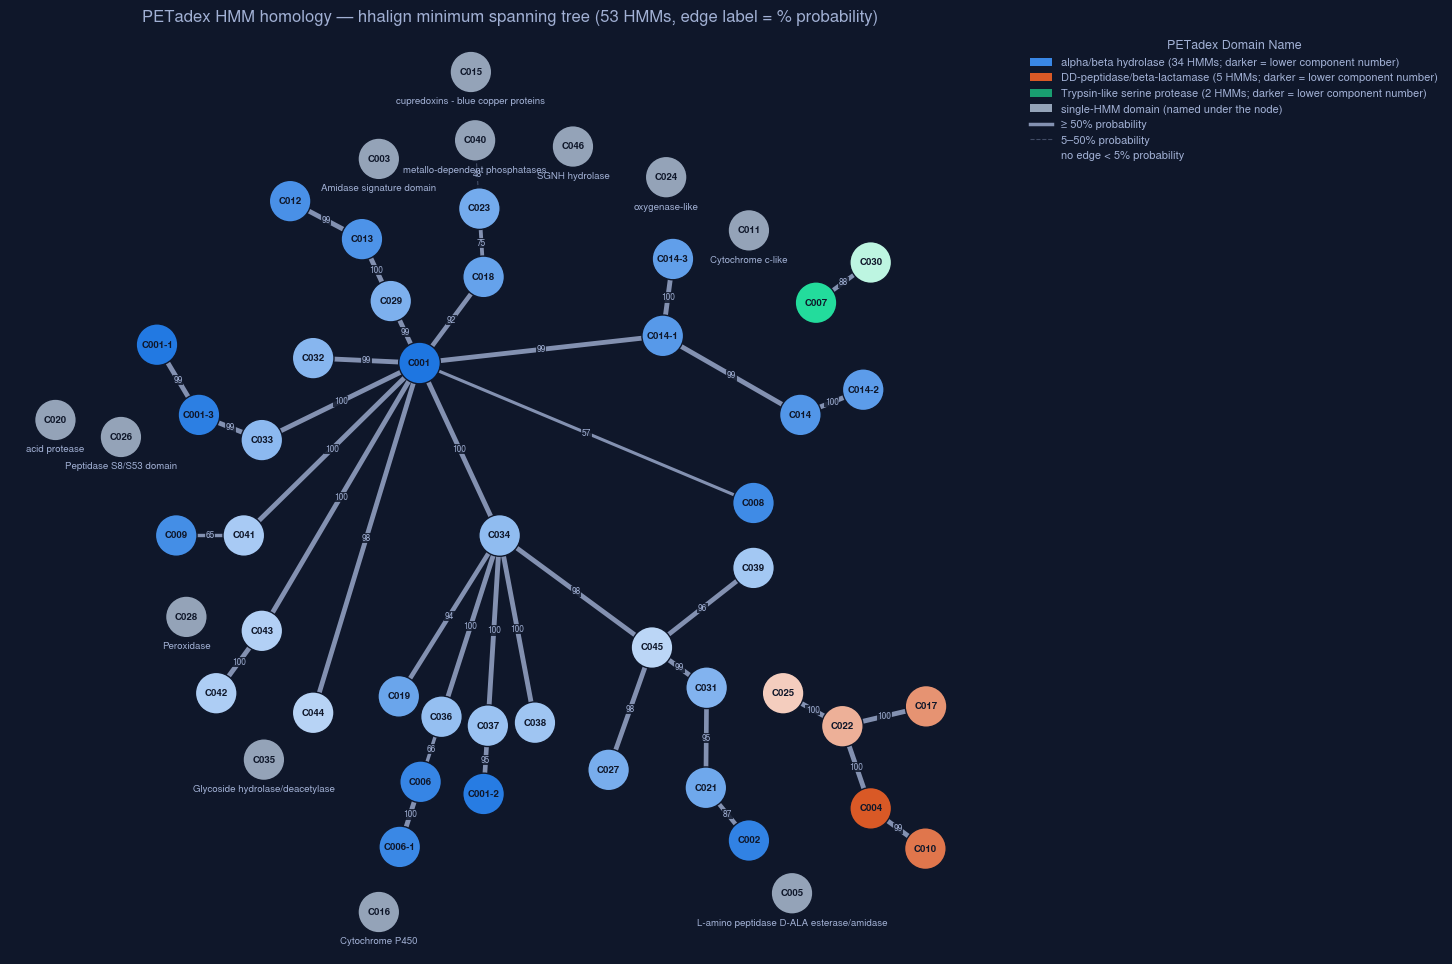

Saved minimum spanning tree -> ./4_hmm_creation/images/hmm_homology_mst.png

3 clusters joined by ≥ 50% tree edges, 12 unclustered HMMs
  [alpha/beta hydrolase] C001, C001-1, C001-2, C001-3, C002, C006, C006-1, C008, C009, C012, C013, C014, C014-1, C014-2, C014-3, C018, C019, C021, C023, C027, C029, C031, C032, C033, C034, C036, C037, C038, C039, C041, C042, C043, C044, C045
  [DD-peptidase/beta-lactamase] C004, C010, C017, C022, C025
  [Trypsin-like serine protease] C007, C030
  unclustered: C003 (Amidase signature domain), C005 (L-amino peptidase D-ALA esterase/amidase), C011 (Cytochrome c-like), C015 (cupredoxins - blue copper proteins), C016 (Cytochrome P450), C020 (acid protease), C024 (oxygenase-like), C026 (Peptidase S8/S53 domain), C028 (Peroxidase), C035 (Glycoside hydrolase/deacetylase), C040 (metallo-dependent phosphatases), C046 (SGNH hydrolase)

hmm_a    hmm_b     probability  domains
C013     C029           100.0%  alpha/beta hydrolase
C014     C014-2         100.0%  alph

In [13]:
# ───────────── #
# SCRIPT SET UP #
# ───────────── #
print("Starting up...")

import colorsys
import csv
import math
import os
import re
import sys
from collections import defaultdict
from itertools import combinations

import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# ─── INPUT ─── #
ALIGNMENT_RESULTS_DIRECTORY = "./4_hmm_creation/working/hhalign/hhalign_results" # {query}__{template}.hhr
HMM_ANNOTATIONS_CSV = "../s3/3_msa_cleaning/plasticome.v2.sequence_annotations.csv" # first column is "PETadex Domain Name"

# ─── OUTPUT ─── #
HMM_HOMOLOGY_OUTPUT = "./4_hmm_creation/working/hhalign/hhalign_summary_results.csv" # each HMM alignment pair with the probability of homology
HMM_HOMOLOGY_MST_IMAGE = "./4_hmm_creation/images/hmm_homology_mst.png"
os.makedirs(os.path.dirname(HMM_HOMOLOGY_MST_IMAGE), exist_ok=True)

# ─── PARAMETERS ─── #
MIN_NODE_GAP = 0.7 # layout units (1 = one tree ring) between neighbouring HMMs on the same ring
STRONG_HOMOLOGY = 50.0 # % probability; weaker tree edges are drawn dashed and faint, and don't join clusters
MIN_DRAWN_HOMOLOGY = 5.0 # % probability; tree edges below this are not drawn (the HMMs are unrelated)

# ─── PLOT STYLE (matches 2.4.2) ─── #
BACKGROUND_COLOR = "#0f172a"
TEXT_COLOR = "#a1b0d4"
DOMAIN_HUES = ["#3987e5", "#d95926", "#199e70"] # blue, orange, aqua; colour-blind safe as a set on a dark background, given to domains with more than one HMM
SINGLE_HMM_DOMAIN_COLOR = "#94a3b8" # domains with one HMM are grey and named under their node, as more than 3 hues stop being distinguishable
UNANNOTATED = "unannotated"
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "Nimbus Sans", "DejaVu Sans"]

HHR_NAME_RE = re.compile(r"^(.+)__(.+)\.hhr$")
HIT_STATS_RE = re.compile(r"([A-Za-z_-]+)=(\S+)")


def hmm_sort_key(hmm_name):
    match = re.match(r"C(\d+)(?:-(\d+))?$", hmm_name)
    return (int(match.group(1)), int(match.group(2) or 0)) if match else (sys.maxsize, 0)


# ─────────────────────────────────────── #
# MAKE HMM HOMOLOGY MINIMAL SPANNING TREE #
# ─────────────────────────────────────── #

# ─── LOAD IN ALL THE HHALIGN DATA ─── #
def parse_hhr(path):
    """
    Returns the stats of the top hhalign hit ("No 1" block) as a dict with
    probability (%), e_value, score, aligned_cols and identities (%), or a zero
    probability when hhalign reports no alignment.
    """
    with open(path) as f:
        lines = f.read().splitlines()
    for i, line in enumerate(lines):
        if line.strip() == "No 1":
            stats = dict(HIT_STATS_RE.findall(lines[i + 2]))
            return {
                "probability": float(stats["Probab"]),
                "e_value": float(stats["E-value"]),
                "score": float(stats["Score"]),
                "aligned_cols": int(stats["Aligned_cols"]),
                "identities": float(stats["Identities"].rstrip("%")),
            }
    return {"probability": 0.0, "e_value": float("nan"), "score": float("nan"), "aligned_cols": 0, "identities": float("nan")}


alignments = {} # (query, template) -> top hit stats
for filename in sorted(os.listdir(ALIGNMENT_RESULTS_DIRECTORY)):
    match = HHR_NAME_RE.match(filename)
    if match:
        alignments[match.groups()] = parse_hhr(os.path.join(ALIGNMENT_RESULTS_DIRECTORY, filename))

hmm_names = sorted({name for pair in alignments for name in pair}, key=hmm_sort_key)
n_expected = len(hmm_names) * (len(hmm_names) - 1)
print(f"Loaded {len(alignments):,}/{n_expected:,} hhalign results for {len(hmm_names)} HMMs from {ALIGNMENT_RESULTS_DIRECTORY}")

domain_by_component = {} # component_id -> PETadex Domain Name
with open(HMM_ANNOTATIONS_CSV, newline="") as f:
    for row in csv.DictReader(f):
        for component_id in filter(None, re.split(r"[,;\s]+", row["component_ids"])):
            domain_by_component[component_id] = row["PETadex Domain Name"]
domain_by_hmm = {hmm_name: domain_by_component.get(hmm_name, UNANNOTATED) for hmm_name in hmm_names}
unannotated = [hmm_name for hmm_name, domain in domain_by_hmm.items() if domain == UNANNOTATED]
print(f"Annotated {len(hmm_names) - len(unannotated)}/{len(hmm_names)} HMMs with a PETadex Domain Name" + (f" (unannotated: {', '.join(unannotated)})" if unannotated else ""))

# ─── CREATE SUMMARY CSV ─── #
"""
ONE ROW PER UNORDERED HMM PAIR
hhalign IS NOT SYMMETRIC, SO KEEP BOTH DIRECTIONS AND USE THE HIGHER PROBABILITY AS THE PAIR'S PROBABILITY
"""
summary_rows = []
for hmm_a, hmm_b in combinations(hmm_names, 2):
    forward, reverse = alignments.get((hmm_a, hmm_b)), alignments.get((hmm_b, hmm_a))
    best = max(filter(None, (forward, reverse)), key=lambda s: s["probability"], default=None)
    if best is None:
        continue
    summary_rows.append({
        "hmm_a": hmm_a,
        "hmm_b": hmm_b,
        "domain_a": domain_by_hmm[hmm_a],
        "domain_b": domain_by_hmm[hmm_b],
        "probability_ab": forward["probability"] if forward else "",
        "probability_ba": reverse["probability"] if reverse else "",
        "probability": best["probability"],
        "e_value": min(s["e_value"] for s in filter(None, (forward, reverse))),
        "aligned_cols": best["aligned_cols"],
        "identities": best["identities"],
    })

with open(HMM_HOMOLOGY_OUTPUT, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(summary_rows[0]))
    writer.writeheader()
    writer.writerows(summary_rows)
print(f"Wrote {len(summary_rows):,} HMM pairs -> {HMM_HOMOLOGY_OUTPUT}")

# ─── CREATE MINIMAL SPANNING TREE ─── #
"""
The plot will be nodes = HMM, edges = probability of homology.
Colour by PETadex Domain Name, and colour components by differing shades of the domain colour
"""
graph = nx.Graph()
graph.add_nodes_from(hmm_names)
for row in summary_rows:
    graph.add_edge(row["hmm_a"], row["hmm_b"],
                   distance=1 - row["probability"] / 100, # minimum distance tree = most probable homology tree
                   probability=row["probability"])
tree = nx.minimum_spanning_tree(graph, weight="distance")

# ─── DOMAIN COLOURS, WITH EACH COMPONENT A DIFFERENT SHADE OF ITS DOMAIN COLOUR ─── #
"""
DOMAINS WITH MORE THAN ONE HMM GET A HUE IN FIXED ORDER (MOST HMMS FIRST), AND EACH OF THEIR COMPONENTS A SHADE OF IT
SINGLE-HMM (AND UNANNOTATED) DOMAINS ARE GREY AND NAMED UNDER THEIR NODE
"""
hmms_by_domain = defaultdict(list) # domain -> [hmm_name, ...] in component order
for hmm_name in hmm_names:
    hmms_by_domain[domain_by_hmm[hmm_name]].append(hmm_name)
multi_hmm_domains = sorted((d for d, members in hmms_by_domain.items() if len(members) > 1 and d != UNANNOTATED),
                           key=lambda d: (-len(hmms_by_domain[d]), d))
if len(multi_hmm_domains) > len(DOMAIN_HUES):
    raise ValueError(f"{len(multi_hmm_domains)} domains have more than one HMM, but only {len(DOMAIN_HUES)} DOMAIN_HUES are defined")
domain_color = dict(zip(multi_hmm_domains, map(to_rgb, DOMAIN_HUES)))

node_color = {hmm_name: to_rgb(SINGLE_HMM_DOMAIN_COLOR) for hmm_name in hmm_names}
for domain in multi_hmm_domains:
    members = hmms_by_domain[domain]
    hue, _, saturation = colorsys.rgb_to_hls(*domain_color[domain])
    for i, hmm_name in enumerate(members):
        node_color[hmm_name] = colorsys.hls_to_rgb(hue, 0.5 + 0.35 * i / (len(members) - 1), saturation) # darkest to lightest in component order

# ─── DRAW THE TREE ─── #
def radial_tree_layout(tree):
    """
    Places the tree's centre HMM in the middle and every other HMM on the ring
    of its depth from it, giving each branch an angular wedge proportional to
    its number of leaves so branches never cross. Each ring is pushed out far
    enough that neighbouring HMMs on it are at least MIN_NODE_GAP apart.
    Probability is shown by edge width and label, not edge length.
    """
    root = min(nx.center(tree), key=hmm_sort_key)
    children = defaultdict(list) # node -> [child, ...] in component order
    for parent, child in nx.bfs_edges(tree, root, sort_neighbors=lambda nodes: sorted(nodes, key=hmm_sort_key)):
        children[parent].append(child)

    n_leaves = {}
    for node in reversed(list(nx.bfs_tree(tree, root))): # children are always counted before their parent
        n_leaves[node] = sum(n_leaves[child] for child in children[node]) or 1

    angles, depths = {root: 0.0}, {root: 0} # node -> angle (radians), node -> ring
    def place(node, start_angle, end_angle):
        angle = start_angle
        for child in children[node]:
            wedge = (end_angle - start_angle) * n_leaves[child] / n_leaves[node]
            angles[child], depths[child] = angle + wedge / 2, depths[node] + 1
            place(child, angle, angle + wedge)
            angle += wedge
    place(root, 0.0, 2 * math.pi)

    radii = {0: 0.0} # ring -> radius
    for depth in range(1, max(depths.values()) + 1):
        ring = sorted(angles[node] for node in angles if depths[node] == depth)
        smallest_gap = min(b - a for a, b in zip(ring, ring[1:] + [ring[0] + 2 * math.pi])) # a single-HMM ring has one 2π gap
        radii[depth] = max(radii[depth - 1] + 1, MIN_NODE_GAP / smallest_gap)

    return {node: (radii[depths[node]] * math.cos(angles[node]), radii[depths[node]] * math.sin(angles[node])) for node in angles}


positions = radial_tree_layout(tree)
strong_edges = [(a, b) for a, b, p in tree.edges(data="probability") if p >= STRONG_HOMOLOGY]
weak_edges = [(a, b) for a, b, p in tree.edges(data="probability") if MIN_DRAWN_HOMOLOGY <= p < STRONG_HOMOLOGY]

fig, ax = plt.subplots(figsize=(16, 12), facecolor=BACKGROUND_COLOR)
ax.set_facecolor(BACKGROUND_COLOR)
nx.draw_networkx_edges(tree, positions, edgelist=strong_edges, ax=ax, edge_color=TEXT_COLOR, alpha=0.8,
                       width=[0.5 + 3 * tree.edges[e]["probability"] / 100 for e in strong_edges])
nx.draw_networkx_edges(tree, positions, edgelist=weak_edges, ax=ax, edge_color=TEXT_COLOR, alpha=0.35, width=0.8, style="dashed")
nx.draw_networkx_edge_labels(tree, positions, ax=ax, rotate=False, font_size=6, font_color=TEXT_COLOR,
                             edge_labels={(a, b): f"{tree.edges[a, b]['probability']:.0f}" for a, b in strong_edges + weak_edges},
                             bbox={"facecolor": BACKGROUND_COLOR, "edgecolor": "none", "alpha": 0.85, "pad": 0.5})
nx.draw_networkx_nodes(tree, positions, ax=ax, nodelist=hmm_names, node_color=[node_color[h] for h in hmm_names],
                       node_size=900, edgecolors=BACKGROUND_COLOR, linewidths=1.0)
nx.draw_networkx_labels(tree, positions, ax=ax, font_size=7, font_weight="bold", font_color=BACKGROUND_COLOR)
for hmm_name in hmm_names:
    if domain_by_hmm[hmm_name] not in domain_color:
        ax.annotate(domain_by_hmm[hmm_name], positions[hmm_name], xytext=(0, -18), textcoords="offset points",
                    ha="center", va="top", fontsize=7, color=TEXT_COLOR)

domain_handles = [Patch(facecolor=domain_color[d], edgecolor="none", label=f"{d} ({len(hmms_by_domain[d])} HMMs; darker = lower component number)")
                  for d in multi_hmm_domains]
domain_handles.append(Patch(facecolor=SINGLE_HMM_DOMAIN_COLOR, edgecolor="none", label="single-HMM domain (named under the node)"))
edge_handles = [Line2D([0], [0], color=TEXT_COLOR, lw=2.5, alpha=0.8, label=f"≥ {STRONG_HOMOLOGY:g}% probability"),
                Line2D([0], [0], color=TEXT_COLOR, lw=0.8, alpha=0.35, ls="--", label=f"{MIN_DRAWN_HOMOLOGY:g}–{STRONG_HOMOLOGY:g}% probability"),
                Line2D([], [], linestyle="none", label=f"no edge < {MIN_DRAWN_HOMOLOGY:g}% probability")]
legend = ax.legend(handles=domain_handles + edge_handles, title="PETadex Domain Name", loc="upper left",
                   bbox_to_anchor=(1.01, 1.0), fontsize=8, title_fontsize=9, frameon=False, labelcolor=TEXT_COLOR)
legend.get_title().set_color(TEXT_COLOR)

ax.set_title(f"PETadex HMM homology — hhalign minimum spanning tree ({len(hmm_names)} HMMs, edge label = % probability)", color=TEXT_COLOR)
ax.axis("off")
fig.subplots_adjust(right=0.75)
plt.savefig(HMM_HOMOLOGY_MST_IMAGE, facecolor=BACKGROUND_COLOR, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Saved minimum spanning tree -> {HMM_HOMOLOGY_MST_IMAGE}")

# ─── REPORT CLUSTERS (TREE EDGES ≥ STRONG_HOMOLOGY) AND CROSS-DOMAIN EDGES ─── #
clusters = sorted(nx.connected_components(tree.edge_subgraph(strong_edges).copy()), key=lambda c: min(map(hmm_sort_key, c)))
singletons = [h for h in hmm_names if not any(h in c for c in clusters)]
print(f"\n{len(clusters)} clusters joined by ≥ {STRONG_HOMOLOGY:g}% tree edges, {len(singletons)} unclustered HMMs")
for cluster in clusters:
    members = sorted(cluster, key=hmm_sort_key)
    cluster_domains = sorted({domain_by_hmm[h] for h in members})
    flag = "  <-- MIXED DOMAINS" if len(cluster_domains) > 1 else ""
    print(f"  [{' | '.join(cluster_domains)}] {', '.join(members)}{flag}")
if singletons:
    print(f"  unclustered: {', '.join(f'{h} ({domain_by_hmm[h]})' for h in singletons)}")

print(f"\n{'hmm_a':<9}{'hmm_b':<9}{'probability':>12}  domains")
for a, b, p in sorted(tree.edges(data="probability"), key=lambda e: -e[2]):
    a, b = sorted((a, b), key=hmm_sort_key)
    domains_text = domain_by_hmm[a] if domain_by_hmm[a] == domain_by_hmm[b] else f"{domain_by_hmm[a]} / {domain_by_hmm[b]}  <-- CROSS-DOMAIN"
    print(f"{a:<9}{b:<9}{p:>11.1f}%  {domains_text}")

# Summary
HMMs were created using the seed MSAs generated in 3_msa_cleaning using a pipeline that is comparable to JACKhmmer. HMMs were built using HMMbuild, and then the catalytic match states (as per 3_msa_cleaning annotations), were annotated on the HMMs. The HMMs were searched against the NCBI nr homologs (<1.0E-10), and any sequence that was below the e-value cut-off of 1.0E-10 and contained all of the canonical catalytic residues were used to create a new alignment that serves as the seed MSA for the next iteration of the pipeline. Match and insert state annotations were progated from the HMM and any column of the alignment that had an occupancy below 0.7 was declared an insert state. The pipeline was then repeated for a total of 4 iterations.

The quality of the HMMs were visualized through the count of complete, partial and canonical HMM hits on the hold-off set (NCBI nr homologs: 1.0E-5 < x <1.0E-10), HMM coverage of AFRAGMENTER predicted catalytic domains, and manual verification of the HMM hit ranges and annotations. The similaritiies of these HMMs were visualized using a minimal spanning tree of the hhalign predicted probability of homologies between each HMM (hmmemit, hhmake HMM conversion).
